# Retinal Disease Detection Using Deep Learning on OCT Images
## Step 7 – Model Evaluation

**Objective:** Evaluate the trained Custom CNN, ResNet18, VGG16, MobileNetV2 and DenseNet121 models on the same unseen OCT test images.

This notebook:
- Calculates accuracy, macro/weighted precision, recall and F1-score.
- Generates confusion matrices and class-wise classification reports.
- Compares model performance.
- Displays misclassified OCT images and common confusion patterns.
- Saves evaluation tables and plots to Google Drive.

**Important evaluation rule:** Do not train, tune, or select models using the test set. This notebook only loads trained checkpoints and evaluates them. If a checkpoint is missing, that model is reported as unavailable rather than evaluated with random weights.

**Current known checkpoint:** Step 6's tuned ResNet18 checkpoint is expected at `Step6_Results/step6_best_model.pt`. Add the other four trained checkpoint paths in the configuration cell before running the full comparison.



## 1. Install and import libraries
Run the install cell only if a package is missing in your Colab runtime.

In [ ]:
%pip install -q datasets scikit-learn seaborn pillow tqdm

In [ ]:
import os
import json
import time
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models

from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


## 2. Mount Google Drive and define paths
The Step 6 checkpoint and preprocessing configuration are loaded from the folder created at the end of Step 6.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

BASE_DIR = Path("/content/drive/MyDrive/Colab Notebooks")
STEP6_DIR = BASE_DIR / "Step6_Results"
STEP7_DIR = BASE_DIR / "Step7_Results"
STEP7_DIR.mkdir(parents=True, exist_ok=True)

CONFIG_PATH = STEP6_DIR / "optimization_config.json"
RESNET18_CHECKPOINT = STEP6_DIR / "step6_best_model.pt"

# The Step 6 cache is preferred because it preserves the test images used
# during the previous experiments, if X_test and y_test are included.
CACHE_PATH = BASE_DIR / "oct_cache_tl_112_600_42.npz"

print("Step 6 folder exists:", STEP6_DIR.exists())
print("Step 6 config exists:", CONFIG_PATH.exists())
print("ResNet18 checkpoint exists:", RESNET18_CHECKPOINT.exists())
print("Dataset cache exists:", CACHE_PATH.exists())

Mounted at /content/drive
Step 6 folder exists: True
Step 6 config exists: True
ResNet18 checkpoint exists: True
Dataset cache exists: False


## 3. Load the saved preprocessing configuration

In [ ]:
if CONFIG_PATH.exists():
    with open(CONFIG_PATH, "r") as f:
        step6_config = json.load(f)
else:
    step6_config = {}

CLASS_NAMES = step6_config.get(
    "class_names", ["CNV", "DME", "DRUSEN", "NORMAL"]
)
IMG_SIZE = int(step6_config.get("img_size", 112))
PIXEL_MEAN = step6_config.get("pixel_mean", 0.5)
PIXEL_STD = step6_config.get("pixel_std", 0.5)

def as_channel_values(value, channels):
    if isinstance(value, (int, float)):
        return [float(value)] * channels
    value = list(value)
    if len(value) == 1:
        return value * channels
    if len(value) != channels:
        raise ValueError(f"Expected 1 or {channels} normalization values; got {value}")
    return [float(v) for v in value]

print("Classes:", CLASS_NAMES)
print("Image size:", IMG_SIZE)
print("Pixel mean:", PIXEL_MEAN)
print("Pixel std:", PIXEL_STD)

Classes: ['CNV', 'DME', 'DRUSEN', 'NORMAL']
Image size: 112
Pixel mean: 0.1923047141650778
Pixel std: 0.21254495714415583


## 4. Load the exact held-out test arrays

The notebook first looks for `X_test` and `y_test` in the Step 6 NPZ cache. This is preferred because it is intended to preserve the exact test subset used in the earlier evaluation.

If the cache does not contain test arrays, the fallback loads the Hugging Face `test` split and selects up to 250 images per class using a fixed seed. **That fallback may not be the identical test subset used in Step 6**, so use the cache whenever possible.

In [ ]:
def load_test_arrays_from_cache(cache_path):
    data = np.load(cache_path, allow_pickle=False)
    print("Cache keys:", data.files)
    x_key = next((k for k in ["X_test", "x_test", "test_images"] if k in data.files), None)
    y_key = next((k for k in ["y_test", "Y_test", "test_labels"] if k in data.files), None)
    if x_key is None or y_key is None:
        return None, None
    return data[x_key], data[y_key]

X_test = y_test = None
if CACHE_PATH.exists():
    X_test, y_test = load_test_arrays_from_cache(CACHE_PATH)

if X_test is None:
    print("Test arrays were not found in the cache. Loading the Hugging Face test split.")
    from datasets import load_dataset
    ds = load_dataset("zacharielegault/Kermany2017-OCT")
    if "test" not in ds:
        raise KeyError(f"No 'test' split found. Available splits: {list(ds.keys())}")

    test_split = ds["test"]
    label_names = test_split.features["label"].names
    rng = np.random.default_rng(SEED)
    selected = []
    for class_idx, class_name in enumerate(CLASS_NAMES):
        indices = [i for i, lab in enumerate(test_split["label"]) if lab == class_idx]
        if len(indices) == 0:
            raise ValueError(f"No test images found for class {class_name}")
        chosen = rng.choice(indices, size=min(250, len(indices)), replace=False)
        selected.extend([(int(i), class_idx) for i in chosen])

    rng.shuffle(selected)
    images, labels = [], []
    for idx, lab in selected:
        im = test_split[int(idx)]["image"].convert("L").resize((IMG_SIZE, IMG_SIZE))
        images.append(np.asarray(im, dtype=np.uint8))
        labels.append(lab)
    X_test = np.stack(images)
    y_test = np.asarray(labels, dtype=np.int64)
    print("WARNING: Fallback test subset generated from HF test split; confirm it matches Step 6.")

X_test = np.asarray(X_test)
y_test = np.asarray(y_test)

if y_test.ndim > 1:
    y_test = np.argmax(y_test, axis=1)
y_test = y_test.astype(np.int64)

# Convert NHWC grayscale/RGB arrays to a standard N,H,W or N,C,H,W layout.
if X_test.ndim == 4 and X_test.shape[-1] in (1, 3):
    X_test = np.transpose(X_test, (0, 3, 1, 2))

print("X_test shape:", X_test.shape, X_test.dtype)
print("y_test shape:", y_test.shape)
print("Test class counts:")
display(pd.Series(y_test).map(dict(enumerate(CLASS_NAMES))).value_counts().reindex(CLASS_NAMES, fill_value=0).to_frame("images"))

assert len(X_test) == len(y_test)
assert set(np.unique(y_test)).issubset(set(range(len(CLASS_NAMES))))

Test arrays were not found in the cache. Loading the Hugging Face test split.


README.md:   0%|          | 0.00/2.79k [00:00<?, ?B/s]

data/train-00000-of-00016.parquet: reconstructing file:   0%|          |  0.00B /  369MB            

data/train-00000-of-00016.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00016.parquet: reconstructing file:   0%|          |  0.00B /  473MB            

data/train-00001-of-00016.parquet: downloading bytes:           |  0.00B            

... (30 outputs left out)

Generating train split:   0%|          | 0/108309 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

X_test shape: (1000, 112, 112) uint8
y_test shape: (1000,)
Test class counts:


,images
CNV,250
DME,250
DRUSEN,250
NORMAL,250


## 5. Build a consistent test Dataset and DataLoader
For pretrained architectures, grayscale OCT scans are repeated across three channels. The saved Step 6 mean and standard deviation are used when available.

In [ ]:
class OCTTestDataset(Dataset):
    def __init__(self, images, labels, rgb=False, image_size=112,
                 mean=0.5, std=0.5):
        self.images = images
        self.labels = labels
        self.rgb = rgb
        self.image_size = image_size
        self.mean = mean
        self.std = std

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        arr = np.asarray(self.images[idx])

        if arr.ndim == 2:
            arr = arr[None, :, :]
        elif arr.ndim == 3 and arr.shape[0] not in (1, 3):
            arr = np.transpose(arr, (2, 0, 1))

        x = torch.as_tensor(arr, dtype=torch.float32)

        # Convert pixel values to [0, 1] when the source is uint8 or 0-255.
        if x.max() > 1.5:
            x = x / 255.0

        if self.rgb and x.shape[0] == 1:
            x = x.repeat(3, 1, 1)
        elif not self.rgb and x.shape[0] == 3:
            x = x.mean(dim=0, keepdim=True)

        channels = x.shape[0]
        mean = torch.tensor(as_channel_values(self.mean, channels), dtype=torch.float32).view(channels, 1, 1)
        std = torch.tensor(as_channel_values(self.std, channels), dtype=torch.float32).view(channels, 1, 1)

        # If cache values are already normalized (contain negatives), do not normalize twice.
        if x.min() >= 0:
            x = (x - mean) / torch.clamp(std, min=1e-8)

        return x, int(self.labels[idx])

BATCH_SIZE = 64
NUM_WORKERS = 2 if device.type == "cuda" else 0
print("Test loader settings ready. Batch size:", BATCH_SIZE)

Test loader settings ready. Batch size: 64


## 6. Configure model checkpoint paths

The ResNet18 checkpoint path is populated from Step 6. For the other models, update the paths below to the actual checkpoint files created during model development.

Expected checkpoint formats:
- A plain PyTorch `state_dict`, or
- A dictionary containing `model_state_dict`, `state_dict`, or `state`.

**Do not point a model name to a checkpoint from a different architecture.** The classifier output layer must have four classes.

In [ ]:
MODEL_CHECKPOINTS = {
    "Custom CNN": BASE_DIR / "Step5_Results" / "custom_cnn_best.pt",
    "ResNet18": RESNET18_CHECKPOINT,
    "VGG16": BASE_DIR / "Step5_Results" / "vgg16_best.pt",
    "MobileNetV2": BASE_DIR / "Step5_Results" / "mobilenet_v2_best.pt",
    "DenseNet121": BASE_DIR / "Step5_Results" / "densenet121_best.pt",
}

# Edit these paths if your checkpoints are stored in another folder.
checkpoint_status = pd.DataFrame([
    {"model": name, "checkpoint": str(path), "exists": Path(path).exists()}
    for name, path in MODEL_CHECKPOINTS.items()
])
display(checkpoint_status)

missing = checkpoint_status.loc[~checkpoint_status["exists"], "model"].tolist()
if missing:
    print("Checkpoint files not found for:", missing)
    print("Those models will be skipped; no random/untrained weights will be evaluated.")

,model,checkpoint,exists
0,Custom CNN,/content/drive/MyDrive/Colab Notebooks/Step5_R...,False
1,ResNet18,/content/drive/MyDrive/Colab Notebooks/Step6_R...,True
2,VGG16,/content/drive/MyDrive/Colab Notebooks/Step5_R...,False
3,MobileNetV2,/content/drive/MyDrive/Colab Notebooks/Step5_R...,False
4,DenseNet121,/content/drive/MyDrive/Colab Notebooks/Step5_R...,False


Checkpoint files not found for: ['Custom CNN', 'VGG16', 'MobileNetV2', 'DenseNet121']
Those models will be skipped; no random/untrained weights will be evaluated.


## 7. Define the model architectures
The torchvision architectures use the standard four-class classifier heads. The Custom CNN definition is imported from the saved Step 6 notebook when that notebook is available.

In [ ]:
def load_custom_cnn_definition():
    import nbformat
    step6_nb_path = BASE_DIR / "Step6_Model_Optimization_Regularization.ipynb"
    if not step6_nb_path.exists():
        raise FileNotFoundError(
            "Step 6 notebook not found. Set the correct path or provide the OCTCNN class definition."
        )
    notebook = nbformat.read(step6_nb_path, as_version=4)
    for cell in notebook.cells:
        if cell.cell_type == "code" and "class OCTCNN" in cell.source:
            exec(cell.source, globals())
            if "OCTCNN" in globals():
                print("Loaded OCTCNN definition from:", step6_nb_path)
                return
    raise RuntimeError("Could not find 'class OCTCNN' in the Step 6 notebook.")

def build_model(model_name):
    n_classes = len(CLASS_NAMES)

    if model_name == "Custom CNN":
        if "OCTCNN" not in globals():
            load_custom_cnn_definition()
        return OCTCNN(n_classes, 1, 32)

    if model_name == "ResNet18":
        model = models.resnet18(weights=None)

        # Match the Step 6 classifier head: Dropout + Linear
        dropout = step6_config.get("hyperparameters", {}).get("dropout", 0.5)
        model.fc = nn.Sequential(
            nn.Dropout(p=dropout),
            nn.Linear(model.fc.in_features, n_classes)
        )
        return model

    if model_name == "VGG16":
        model = models.vgg16(weights=None)
        model.classifier[6] = nn.Linear(
            model.classifier[6].in_features, n_classes
        )
        return model

    if model_name == "MobileNetV2":
        model = models.mobilenet_v2(weights=None)
        model.classifier[1] = nn.Linear(
            model.classifier[1].in_features, n_classes
        )
        return model

    if model_name == "DenseNet121":
        model = models.densenet121(weights=None)
        model.classifier = nn.Linear(
            model.classifier.in_features, n_classes
        )
        return model

    raise ValueError("Unknown model: " + model_name)

print("Corrected model builder.")

def extract_state_dict(checkpoint):
    if isinstance(checkpoint, dict):
        for key in ["model_state_dict", "state_dict", "model", "state"]:
            if key in checkpoint and isinstance(checkpoint[key], dict):
                checkpoint = checkpoint[key]
                break
    if not isinstance(checkpoint, dict):
        raise TypeError("Checkpoint does not contain a state_dict.")
    # Remove DataParallel prefix if present.
    return {k.replace("module.", "", 1) if k.startswith("module.") else k: v
            for k, v in checkpoint.items()}

print("Model builders are ready.")

Corrected model builder.
Model builders are ready.


## 8. Load available trained checkpoints

In [ ]:
RGB_MODELS = {"ResNet18", "VGG16", "MobileNetV2", "DenseNet121"}
loaded_models = {}
load_errors = {}

for model_name, checkpoint_path in MODEL_CHECKPOINTS.items():
    checkpoint_path = Path(checkpoint_path)
    if not checkpoint_path.exists():
        continue

    try:
        model = build_model(model_name)
        checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
        state_dict = extract_state_dict(checkpoint)
        model.load_state_dict(state_dict, strict=True)
        model = model.to(device).eval()
        loaded_models[model_name] = model
        print(f"Loaded {model_name}: {checkpoint_path.name}")
    except Exception as e:
        load_errors[model_name] = str(e)
        print(f"Could not load {model_name}: {e}")

print("\nSuccessfully loaded:", list(loaded_models.keys()))
if load_errors:
    print("\nLoad errors:")
    for name, err in load_errors.items():
        print(name, "->", err)

if not loaded_models:
    raise RuntimeError("No trained model checkpoints were loaded. Correct MODEL_CHECKPOINTS before continuing.")

Loaded ResNet18: step6_best_model.pt

Successfully loaded: ['ResNet18']


## 9. Evaluate all loaded models on the same unseen test set
The evaluation reports macro and weighted metrics. Macro averages give each class equal weight, which is useful for class-wise medical image evaluation.

In [ ]:
def evaluate_model(model_name, model):
    rgb = model_name in RGB_MODELS
    test_ds = OCTTestDataset(
        X_test, y_test, rgb=rgb, image_size=IMG_SIZE,
        mean=PIXEL_MEAN, std=PIXEL_STD
    )
    loader = DataLoader(
        test_ds, batch_size=BATCH_SIZE, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda")
    )

    all_true, all_pred, all_prob = [], [], []
    start = time.time()

    model.eval()
    with torch.inference_mode():
        for xb, yb in loader:
            xb = xb.to(device, non_blocking=True)
            logits = model(xb)
            probs = torch.softmax(logits, dim=1)
            preds = probs.argmax(dim=1)

            all_true.extend(yb.numpy().tolist())
            all_pred.extend(preds.cpu().numpy().tolist())
            all_prob.extend(probs.cpu().numpy().tolist())

    if device.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.time() - start

    y_true = np.asarray(all_true)
    y_pred = np.asarray(all_pred)
    y_prob = np.asarray(all_prob)

    p_macro, r_macro, f1_macro, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=np.arange(len(CLASS_NAMES)),
        average="macro", zero_division=0
    )
    p_weighted, r_weighted, f1_weighted, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=np.arange(len(CLASS_NAMES)),
        average="weighted", zero_division=0
    )
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(CLASS_NAMES)))

    return {
        "model": model_name,
        "y_true": y_true,
        "y_pred": y_pred,
        "y_prob": y_prob,
        "cm": cm,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": p_macro,
        "recall_macro": r_macro,
        "f1_macro": f1_macro,
        "precision_weighted": p_weighted,
        "recall_weighted": r_weighted,
        "f1_weighted": f1_weighted,
        "seconds": elapsed,
        "ms_per_image": elapsed / len(y_true) * 1000
    }

evaluation_results = {}
for model_name, model in loaded_models.items():
    print(f"Evaluating {model_name} ...")
    evaluation_results[model_name] = evaluate_model(model_name, model)
    print(f"  Accuracy={evaluation_results[model_name]['accuracy']:.4f}, "
          f"Macro-F1={evaluation_results[model_name]['f1_macro']:.4f}")

print("Evaluation completed for", len(evaluation_results), "model(s).")

Evaluating ResNet18 ...
  Accuracy=0.8880, Macro-F1=0.8807
Evaluation completed for 1 model(s).


## 10. Overall performance comparison

In [ ]:
comparison_rows = []
for name, result in evaluation_results.items():
    comparison_rows.append({
        "Model": name,
        "Accuracy": result["accuracy"],
        "Macro Precision": result["precision_macro"],
        "Macro Recall": result["recall_macro"],
        "Macro F1": result["f1_macro"],
        "Weighted F1": result["f1_weighted"],
        "Inference ms/image": result["ms_per_image"]
    })

comparison_df = pd.DataFrame(comparison_rows).sort_values(
    "Macro F1", ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Inference ms/image
0,ResNet18,0.888,0.9046,0.888,0.8807,0.8807,4.1137


## 11. Classification report for each model

In [ ]:
class_reports = {}
for name, result in evaluation_results.items():
    print("\n" + "=" * 65)
    print(name)
    print("=" * 65)
    report = classification_report(
        result["y_true"], result["y_pred"],
        labels=np.arange(len(CLASS_NAMES)),
        target_names=CLASS_NAMES,
        digits=4, zero_division=0, output_dict=True
    )
    class_reports[name] = report
    print(classification_report(
        result["y_true"], result["y_pred"],
        labels=np.arange(len(CLASS_NAMES)),
        target_names=CLASS_NAMES,
        digits=4, zero_division=0
    ))


ResNet18
              precision    recall  f1-score   support

         CNV     0.7954    0.9640    0.8716       250
         DME     0.9609    0.9840    0.9723       250
      DRUSEN     1.0000    0.6040    0.7531       250
      NORMAL     0.8621    1.0000    0.9259       250

    accuracy                         0.8880      1000
   macro avg     0.9046    0.8880    0.8807      1000
weighted avg     0.9046    0.8880    0.8807      1000



## 12. Confusion matrices

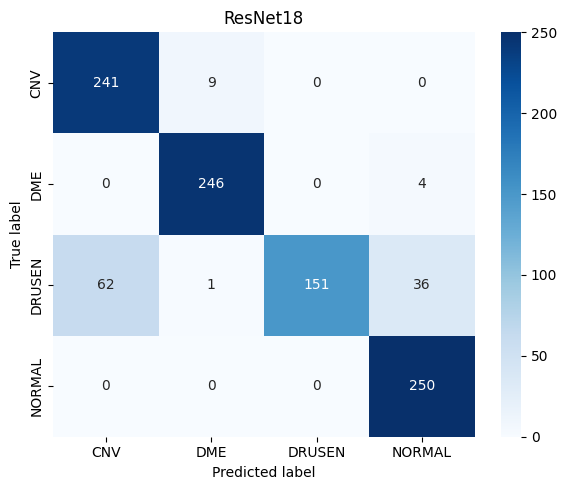

In [ ]:
n_models = len(evaluation_results)
fig, axes = plt.subplots(1, n_models, figsize=(6 * n_models, 5))
if n_models == 1:
    axes = [axes]

for ax, (name, result) in zip(axes, evaluation_results.items()):
    sns.heatmap(
        result["cm"], annot=True, fmt="d", cmap="Blues",
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

plt.tight_layout()
plt.show()

## 13. Normalized confusion matrices

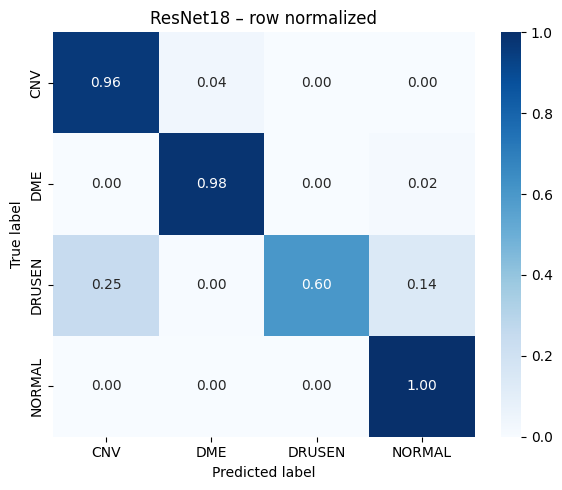

In [ ]:
fig, axes = plt.subplots(1, n_models, figsize=(6 * n_models, 5))
if n_models == 1:
    axes = [axes]

for ax, (name, result) in zip(axes, evaluation_results.items()):
    cm = result["cm"]
    row_sums = cm.sum(axis=1, keepdims=True)
    cm_norm = np.divide(cm, row_sums, out=np.zeros_like(cm, dtype=float), where=row_sums != 0)
    sns.heatmap(
        cm_norm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax
    )
    ax.set_title(name + " – row normalized")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

plt.tight_layout()
plt.show()

## 14. Class-wise precision, recall and F1-score

In [ ]:
class_metric_rows = []
for name, result in evaluation_results.items():
    p, r, f1, support = precision_recall_fscore_support(
        result["y_true"], result["y_pred"],
        labels=np.arange(len(CLASS_NAMES)), zero_division=0
    )
    for i, cls in enumerate(CLASS_NAMES):
        class_metric_rows.append({
            "Model": name, "Class": cls,
            "Precision": p[i], "Recall": r[i],
            "F1-score": f1[i], "Support": support[i]
        })

class_metrics_df = pd.DataFrame(class_metric_rows)
display(class_metrics_df.round(4))

,Model,Class,Precision,Recall,F1-score,Support
0,ResNet18,CNV,0.7954,0.964,0.8716,250
1,ResNet18,DME,0.9609,0.984,0.9723,250
2,ResNet18,DRUSEN,1.0000,0.604,0.7531,250
3,ResNet18,NORMAL,0.8621,1.000,0.9259,250


## 15. Analyze misclassified images
The following cell displays examples for the selected model. Change `ANALYZE_MODEL` to inspect another loaded model.

Model: ResNet18
Misclassified: 112 of 1000
Error rate: 0.112


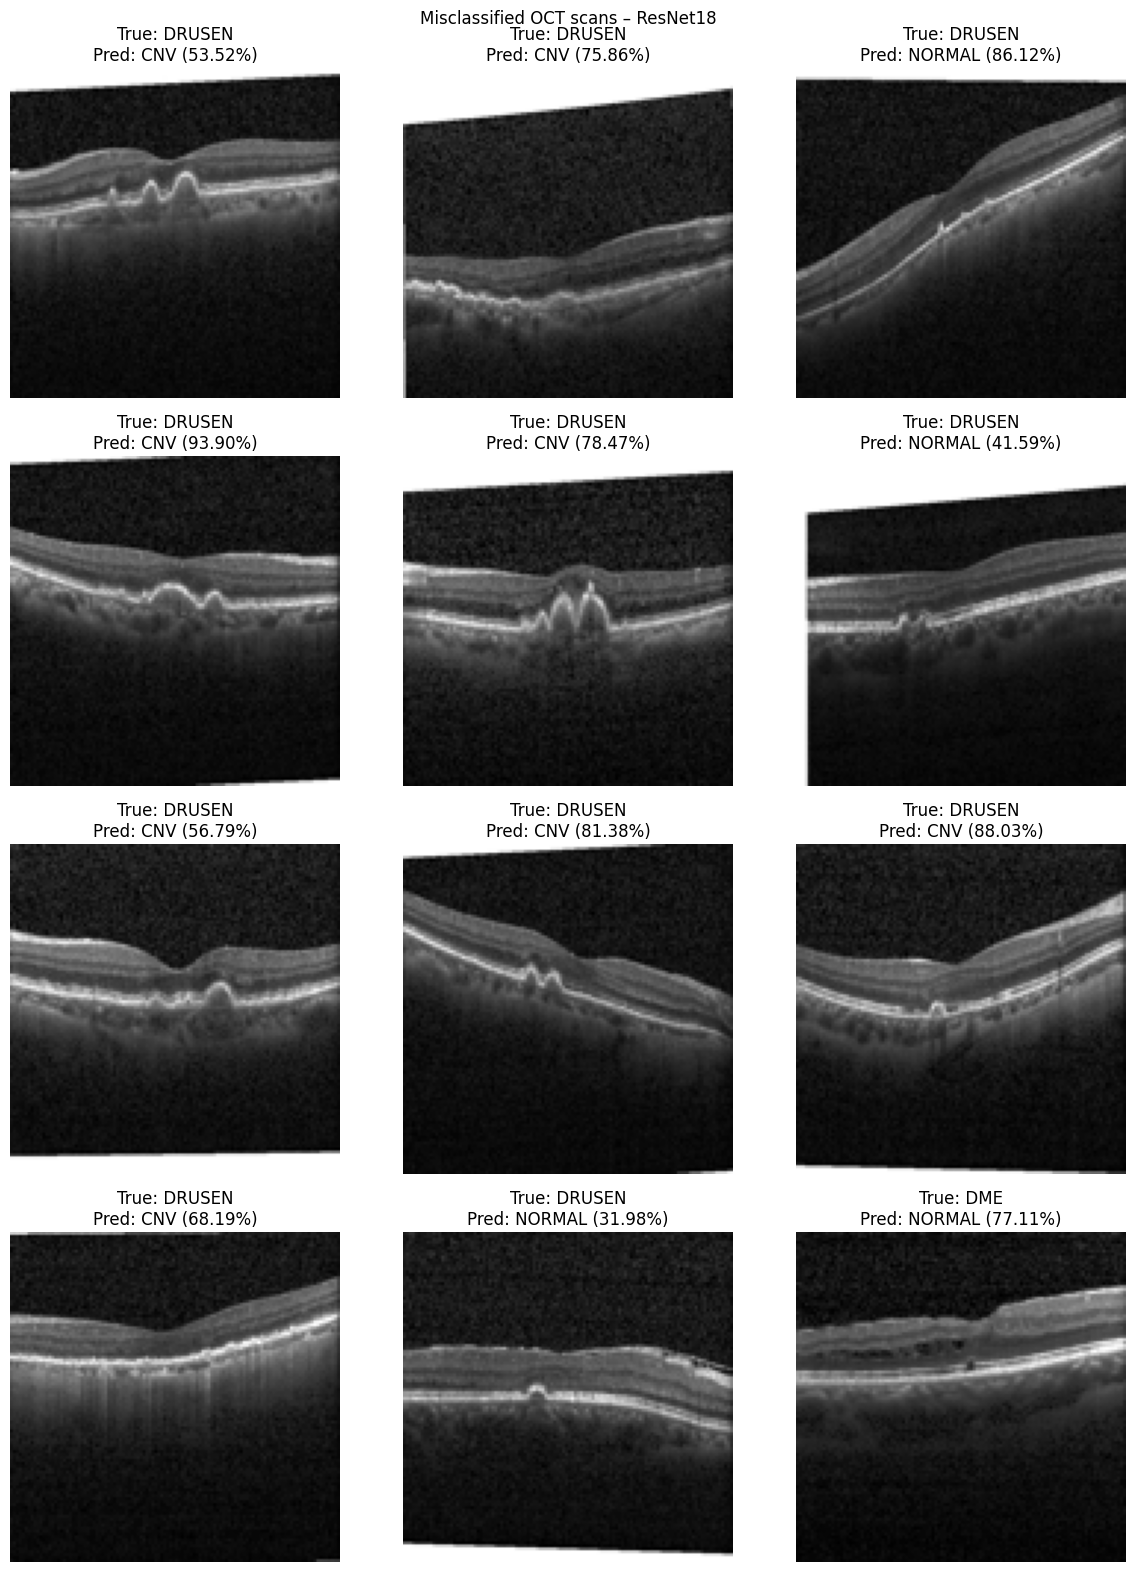

In [ ]:
ANALYZE_MODEL = "ResNet18" if "ResNet18" in evaluation_results else list(evaluation_results.keys())[0]
MAX_MISCLASSIFIED = 12

result = evaluation_results[ANALYZE_MODEL]
wrong_idx = np.where(result["y_true"] != result["y_pred"])[0]

print("Model:", ANALYZE_MODEL)
print("Misclassified:", len(wrong_idx), "of", len(result["y_true"]))
print("Error rate:", round(len(wrong_idx) / len(result["y_true"]), 4))

if len(wrong_idx) == 0:
    print("No misclassified images.")
else:
    show_idx = wrong_idx[:MAX_MISCLASSIFIED]
    ncols = 3
    nrows = int(np.ceil(len(show_idx) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 4 * nrows))
    axes = np.array(axes).reshape(-1)

    for ax, idx in zip(axes, show_idx):
        img = np.asarray(X_test[idx])
        if img.ndim == 3 and img.shape[0] in (1, 3):
            img = np.transpose(img, (1, 2, 0))
        if img.ndim == 3 and img.shape[-1] == 1:
            img = img.squeeze(-1)
        if img.max() > 1:
            img = img / 255.0

        true_name = CLASS_NAMES[result["y_true"][idx]]
        pred_name = CLASS_NAMES[result["y_pred"][idx]]
        confidence = result["y_prob"][idx].max()

        ax.imshow(img, cmap="gray" if img.ndim == 2 else None)
        ax.set_title(f"True: {true_name}\nPred: {pred_name} ({confidence:.2%})")
        ax.axis("off")

    for ax in axes[len(show_idx):]:
        ax.axis("off")

    plt.suptitle(f"Misclassified OCT scans – {ANALYZE_MODEL}")
    plt.tight_layout()
    plt.show()

## 16. Most frequent class-confusion patterns

In [ ]:
confusion_rows = []
for name, result in evaluation_results.items():
    cm = result["cm"].copy()
    np.fill_diagonal(cm, 0)
    for true_idx, pred_idx in zip(*np.where(cm > 0)):
        confusion_rows.append({
            "Model": name,
            "Actual class": CLASS_NAMES[true_idx],
            "Predicted class": CLASS_NAMES[pred_idx],
            "Count": int(cm[true_idx, pred_idx])
        })

confusion_patterns_df = pd.DataFrame(confusion_rows)
if not confusion_patterns_df.empty:
    confusion_patterns_df = confusion_patterns_df.sort_values(
        ["Model", "Count"], ascending=[True, False]
    )
display(confusion_patterns_df.head(30))

,Model,Actual class,Predicted class,Count
2,ResNet18,DRUSEN,CNV,62
4,ResNet18,DRUSEN,NORMAL,36
0,ResNet18,CNV,DME,9
1,ResNet18,DME,NORMAL,4
3,ResNet18,DRUSEN,DME,1


In [ ]:
Misclassification analysis revealed that DRUSEN was the most challenging class for ResNet18. The majority of classification errors occurred when DRUSEN images were predicted as CNV or NORMAL. These errors may reflect similarities in retinal image features or subtle abnormalities that are difficult to distinguish. A smaller number of CNV and DME images were also incorrectly classified. Future improvements could focus on DRUSEN-specific learning strategies, careful image augmentation, visual inspection of errors and external validation.

## 17. Save evaluation outputs to Google Drive

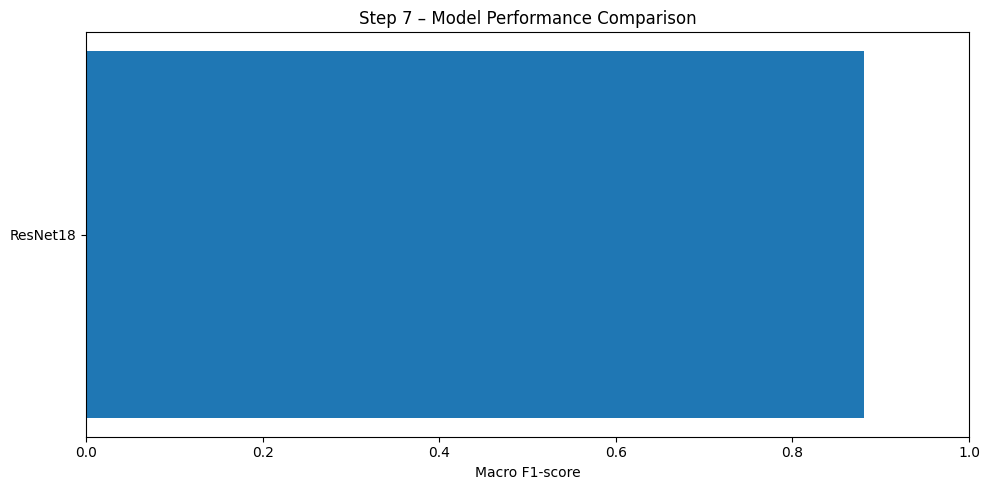

Saved evaluation outputs to: /content/drive/MyDrive/Colab Notebooks/Step7_Results
- step7_classwise_metrics.csv
- step7_confusion_patterns.csv
- step7_macro_f1_comparison.png
- step7_model_comparison.csv
- step7_resnet18_classification_report.csv
- step7_resnet18_confusion_matrix.csv


In [ ]:
# Save summary metrics, per-class metrics, confusion-pattern counts and reports.
comparison_df.to_csv(STEP7_DIR / "step7_model_comparison.csv", index=False)
class_metrics_df.to_csv(STEP7_DIR / "step7_classwise_metrics.csv", index=False)
confusion_patterns_df.to_csv(STEP7_DIR / "step7_confusion_patterns.csv", index=False)

for name, result in evaluation_results.items():
    safe_name = name.lower().replace(" ", "_")
    pd.DataFrame(
        result["cm"], index=CLASS_NAMES, columns=CLASS_NAMES
    ).to_csv(STEP7_DIR / f"step7_{safe_name}_confusion_matrix.csv")

    report_df = pd.DataFrame(class_reports[name]).T
    report_df.to_csv(STEP7_DIR / f"step7_{safe_name}_classification_report.csv")

# Save comparison plot.
plt.figure(figsize=(10, 5))
plot_df = comparison_df.sort_values("Macro F1")
plt.barh(plot_df["Model"], plot_df["Macro F1"])
plt.xlim(0, 1)
plt.xlabel("Macro F1-score")
plt.title("Step 7 – Model Performance Comparison")
plt.tight_layout()
plt.savefig(STEP7_DIR / "step7_macro_f1_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

print("Saved evaluation outputs to:", STEP7_DIR)
for p in sorted(STEP7_DIR.iterdir()):
    print("-", p.name)

In [ ]:
import os

from google.colab import drive
drive.mount('/content/drive')

root = "/content/drive/MyDrive"

checkpoint_files = []

for folder, dirs, files in os.walk(root):
    # Avoid searching large unrelated folders
    dirs[:] = [d for d in dirs if d not in [
        ".ipynb_checkpoints", "node_modules"
    ]]

    for file in files:
        if file.endswith((".pt", ".pth", ".pth.tar")):
            checkpoint_files.append(os.path.join(folder, file))

print("Found model checkpoints:\n")

for path in checkpoint_files:
    print(path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Found model checkpoints:

/content/drive/MyDrive/Colab Notebooks/Step6_Results/step6_best_model.pt


In [ ]:
import torch
import os

checkpoint_path = (
    "/content/drive/MyDrive/Colab Notebooks/"
    "Step6_Results/step6_best_model.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("\nTop-level keys:")
    print(list(checkpoint.keys()))

    if "model_state_dict" in checkpoint:
        state = checkpoint["model_state_dict"]
    elif "state" in checkpoint:
        state = checkpoint["state"]
    else:
        state = checkpoint

    print("\nClassifier-related parameter names:")
    for key in state.keys():
        if key.startswith("fc."):
            print(key, state[key].shape)

    print("\nSaved configuration:")
    print(checkpoint.get("config", "No config found"))

Checkpoint type: <class 'dict'>

Top-level keys:
['model_state_dict', 'config']

Classifier-related parameter names:
fc.1.weight torch.Size([4, 512])
fc.1.bias torch.Size([4])

Saved configuration:
{'best_model': 'resnet18 (tuned)', 'kind': 'pt', 'architecture': 'resnet18', 'hyperparameters': {'lr_body': 0.00011155089629737622, 'lr_head': 0.001, 'dropout': 0.5, 'l2': 1e-05, 'label_smoothing': 0.0}, 'img_size': 112, 'channels': 3, 'pixel_mean': 0.1923047141650778, 'pixel_std': 0.21254495714415583, 'class_names': ['CNV', 'DME', 'DRUSEN', 'NORMAL'], 'val_macro_f1_mean': 0.8941731105647607, 'independent_test_accuracy': 0.94, 'independent_test_macro_f1': 0.9382669771593063, 'n_seeds': 3, 'quick_mode': True, 'seed': 42}


In [ ]:
# Correct ResNet18 loading code
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint_path = (
    "/content/drive/MyDrive/Colab Notebooks/"
    "Step6_Results/step6_best_model.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

# Recreate the exact ResNet18 architecture
resnet18 = models.resnet18(weights=None)

# Match the saved classifier architecture
resnet18.fc = nn.Sequential(
    nn.Dropout(p=0.5),
    nn.Linear(resnet18.fc.in_features, 4)
)

# Load trained weights
resnet18.load_state_dict(checkpoint["model_state_dict"])

resnet18 = resnet18.to(device)
resnet18.eval()

print("ResNet18 loaded successfully!")
print("Device:", device)
print("Classes:", checkpoint["config"]["class_names"])
print("Image size:", checkpoint["config"]["img_size"])

ResNet18 loaded successfully!
Device: cuda
Classes: ['CNV', 'DME', 'DRUSEN', 'NORMAL']
Image size: 112


In [ ]:
#Step 4 — Check your existing dataset and variables
required_variables = [
    "train_loader",
    "val_loader",
    "test_loader",
    "class_names",
    "device"
]

for name in required_variables:
    print(
        name,
        "Available" if name in globals() else "NOT AVAILABLE"
    )

if "class_names" in globals():
    print("\nClasses:", class_names)

if "train_loader" in globals():
    print("Training batches:", len(train_loader))

if "val_loader" in globals():
    print("Validation batches:", len(val_loader))

if "test_loader" in globals():
    print("Testing batches:", len(test_loader))

train_loader NOT AVAILABLE
val_loader NOT AVAILABLE
test_loader NOT AVAILABLE
class_names NOT AVAILABLE
device Available


In [ ]:
# Step 5 — Locate your cached OCT dataset
import os

search_folder = "/content/drive/MyDrive/Colab Notebooks"

print("Searching for OCT dataset cache...\n")

for folder, dirs, files in os.walk(search_folder):
    dirs[:] = [
        d for d in dirs
        if d not in [".ipynb_checkpoints", "__pycache__"]
    ]

    for file in files:
        if file.endswith(".npz") and "oct" in file.lower():
            path = os.path.join(folder, file)
            size_mb = os.path.getsize(path) / (1024 * 1024)

            print("File:", file)
            print("Path:", path)
            print(f"Size: {size_mb:.2f} MB\n")

Searching for OCT dataset cache...



In [ ]:
import os

folder = "/content/drive/MyDrive/Colab Notebooks"

for file in os.listdir(folder):
    if file.endswith(".ipynb"):
        print(file)

loan.ipynb
BankLaon.ipynb
Untitled0.ipynb
Untitled1.ipynb
Untitled2.ipynb
Module_1_worksheet_solved.ipynb
Untitled3.ipynb
Untitled4.ipynb
S V M lung.ipynb
Fraudmain (1).ipynb
Fraud Detection.ipynb
Fraudmain.ipynb
ASLNEW.ipynb
ASL4.ipynb
ASLPrediction.ipynb
Copy of Heart_Disease_Prediction_Fixed.ipynb
Heart_Disease_Prediction_Fixed.ipynb
Python Essentials Part_I.ipynb
RDD_Sample (1).ipynb
ML_Reg.ipynb
Numpy&Pandas (1).ipynb
RDD_Sample.ipynb
Untitled5.ipynb
Copy of Mall Customer.ipynb
Mall Customer.ipynb
py mall.ipynb
Untitled6.ipynb
python practise.ipynb
Numpy&Pandas.ipynb
Untitled7.ipynb
Untitled8.ipynb
Practise.ipynb
Untitled9.ipynb
Untitled10.ipynb
Untitled11.ipynb
skillcept 10.01.2025.ipynb
Copy of skillcept 11.01.2025.ipynb
Untitled12.ipynb
Untitled13.ipynb
Untitled14.ipynb
Untitled15.ipynb
Untitled16.ipynb
12AprilPanda.ipynb
Untitled17.ipynb
Untitled18.ipynb
Untitled19.ipynb
Untitled20.ipynb
Untitled21.ipynb
Simple Linear Regression.ipynb
Untitled23.ipynb
Untitled22.ipynb
Untitled

In [ ]:
import json
import os

base = "/content/drive/MyDrive/Colab Notebooks"

notebooks = [
    "Step1_Dataset_Collection_and_Understanding.ipynb",
    "Step5_Transfer_Learning.ipynb",
    "Step6_Model_Optimization_Regularization.ipynb"
]

keywords = [
    "load_dataset",
    "train_test_split",
    "DataLoader",
    "ImageFolder",
    "np.load",
    "cache",
    "transform"
]

for notebook in notebooks:
    path = os.path.join(base, notebook)

    print("\n" + "=" * 70)
    print("NOTEBOOK:", notebook)

    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    for i, cell in enumerate(data["cells"]):
        if cell["cell_type"] != "code":
            continue

        code = "".join(cell["source"])

        if any(k.lower() in code.lower() for k in keywords):
            print(f"\n--- CELL {i} ---")
            print(code[:2500])


NOTEBOOK: Step1_Dataset_Collection_and_Understanding.ipynb

--- CELL 4 ---
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset, DatasetDict, ClassLabel

sns.set_style("whitegrid")
random.seed(42)
np.random.seed(42)

--- CELL 6 ---
DATASET_ID = "Augusto777/OCT2017"   # change to a full OCT2017 mirror for the complete ~84k images
EXPECTED_CLASSES = ["CNV", "DME", "DRUSEN", "NORMAL"]

ds = load_dataset(DATASET_ID)
if not isinstance(ds, DatasetDict):           # single split -> wrap
    ds = DatasetDict({"train": ds})
print(ds)

NOTEBOOK: Step5_Transfer_Learning.ipynb

--- CELL 2 ---
import os
os.environ["HF_HUB_DISABLE_XET"] = "1"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"

# Folder that CONTAINS "zacharielegault___kermany2017-oct" (the "datasets" folder of your Hugging Face cache), e.g.
#   HF_CACHE_DIR = r"D:

In [ ]:

import os
import time
import numpy as np
from PIL import Image
from datasets import load_dataset

# Reproducibility
SEED = 42
IMG_SIZE = 112
PER_CLASS = 600
VAL_FRACTION = 0.15

rng = np.random.default_rng(SEED)

# Look for the original Step 6 cache
cache_file = "oct_cache_tl_112_600_42.npz"

possible_paths = [
    cache_file,
    "/content/drive/MyDrive/oct_cache_tl_112_600_42.npz",
    "/content/drive/MyDrive/Colab Notebooks/oct_cache_tl_112_600_42.npz",
    "/content/drive/MyDrive/Colab Notebooks/Step6_Results/oct_cache_tl_112_600_42.npz"
]

found_cache = next((p for p in possible_paths if os.path.exists(p)), None)

if found_cache:
    print("Loading existing cache:", found_cache)
    z = np.load(found_cache)
    X_pool, y_pool = z["X_pool"], z["y_pool"]
    X_test, y_test = z["X_test"], z["y_test"]

else:
    print("Cache not found. Loading the original OCT dataset...")
    dataset = load_dataset("zacharielegault/Kermany2017-OCT")

    train_data = dataset["train"]
    test_data = dataset["test"]

    class_names = train_data.features["label"].names
    train_labels_all = train_data.data.column("label").to_numpy()
    test_labels_all = test_data.data.column("label").to_numpy()

    def cache_images(ds, indices, size):
        images = np.empty((len(indices), size, size), dtype=np.uint8)
        start = time.time()

        for k, idx in enumerate(indices):
            images[k] = np.asarray(
                ds[int(idx)]["image"]
                .convert("L")
                .resize((size, size), Image.BILINEAR)
            )

            if (k + 1) % 250 == 0 or k + 1 == len(indices):
                print(f"Processed {k+1}/{len(indices)} images")

        print(f"Time: {time.time() - start:.1f} seconds")
        return images

    # Reproduce the exact Step 6 training sample
    n_classes = len(class_names)

    pool_idx = np.concatenate([
        rng.choice(
            np.where(train_labels_all == c)[0],
            PER_CLASS,
            replace=False
        )
        for c in range(n_classes)
    ])

    pool_idx = rng.permutation(pool_idx)

    X_pool = cache_images(train_data, pool_idx, IMG_SIZE)
    y_pool = train_labels_all[pool_idx]

    # Original independent test set
    X_test = cache_images(
        test_data,
        np.arange(len(test_data)),
        IMG_SIZE
    )
    y_test = test_labels_all

    np.savez_compressed(
        cache_file,
        X_pool=X_pool,
        y_pool=y_pool,
        X_test=X_test,
        y_test=y_test
    )

    print("Dataset cache saved:", cache_file)

# Restore class names if cache was found
if "class_names" not in globals():
    class_names = ["CNV", "DME", "DRUSEN", "NORMAL"]

# Reproduce the exact stratified Step 6 train/validation split
val_idx = np.concatenate([
    rng.permutation(np.where(y_pool == c)[0])[
        :int(PER_CLASS * VAL_FRACTION)
    ]
    for c in range(len(class_names))
])

is_val = np.zeros(len(y_pool), dtype=bool)
is_val[val_idx] = True

X_train = X_pool[~is_val]
y_train = y_pool[~is_val]
X_val = X_pool[is_val]
y_val = y_pool[is_val]

print("\nDATA RESTORED SUCCESSFULLY")
print("Classes:", class_names)
print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

for name, labels in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    print(name, dict(zip(
        class_names,
        np.bincount(labels, minlength=len(class_names))
    )))


Loading existing cache: /content/drive/MyDrive/oct_cache_tl_112_600_42.npz

DATA RESTORED SUCCESSFULLY
Classes: ['CNV', 'DME', 'DRUSEN', 'NORMAL']
Training: (2040, 112, 112) (2040,)
Validation: (360, 112, 112) (360,)
Test: (1000, 112, 112) (1000,)
Train {'CNV': np.int64(510), 'DME': np.int64(510), 'DRUSEN': np.int64(510), 'NORMAL': np.int64(510)}
Validation {'CNV': np.int64(90), 'DME': np.int64(90), 'DRUSEN': np.int64(90), 'NORMAL': np.int64(90)}
Test {'CNV': np.int64(250), 'DME': np.int64(250), 'DRUSEN': np.int64(250), 'NORMAL': np.int64(250)}


In [ ]:
# Step 2 — Create evaluation DataLoaders

import torch
from torch.utils.data import Dataset, DataLoader

# Use the existing device, or select one
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Step 6 normalization values
PIX_MEAN = float(X_train.mean() / 255.0)
PIX_STD = float(X_train.std() / 255.0)

IM_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IM_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

class OCTTestDataset(Dataset):
    def __init__(self, images, labels, rgb=False):
        self.x = torch.from_numpy(images).unsqueeze(1)
        self.y = torch.from_numpy(labels).long()
        self.rgb = rgb

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        x = self.x[idx].float() / 255.0

        if self.rgb:
            x = x.repeat(3, 1, 1)
            x = (x - IM_MEAN) / IM_STD
        else:
            x = (x - PIX_MEAN) / PIX_STD

        return x, self.y[idx]

# Test loaders
test_loader_gray = DataLoader(
    OCTTestDataset(X_test, y_test, rgb=False),
    batch_size=64,
    shuffle=False,
    num_workers=0
)

test_loader_rgb = DataLoader(
    OCTTestDataset(X_test, y_test, rgb=True),
    batch_size=64,
    shuffle=False,
    num_workers=0
)

print("Device:", device)
print("Gray test batches:", len(test_loader_gray))
print("RGB test batches:", len(test_loader_rgb))

xb_gray, yb_gray = next(iter(test_loader_gray))
xb_rgb, yb_rgb = next(iter(test_loader_rgb))

print("Custom CNN input:", xb_gray.shape)
print("Pretrained model input:", xb_rgb.shape)
print("Labels:", yb_gray.shape)


Device: cuda
Gray test batches: 16
RGB test batches: 16
Custom CNN input: torch.Size([64, 1, 112, 112])
Pretrained model input: torch.Size([64, 3, 112, 112])
Labels: torch.Size([64])


In [ ]:
# Step 3 — Load the saved ResNet18 checkpoint

import torch
import torch.nn as nn
from torchvision import models

checkpoint_path = (
    "/content/drive/MyDrive/Colab Notebooks/"
    "Step6_Results/step6_best_model.pt"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

# Rebuild the exact ResNet18 classifier structure
resnet18 = models.resnet18(weights=None)

resnet18.fc = nn.Sequential(
    nn.Dropout(p=0.5),
    nn.Linear(resnet18.fc.in_features, len(class_names))
)

resnet18.load_state_dict(checkpoint["model_state_dict"])

resnet18 = resnet18.to(device)
resnet18.eval()

print("ResNet18 loaded successfully!")
print("Architecture:", checkpoint["config"]["architecture"])
print("Best model:", checkpoint["config"]["best_model"])
print("Image size:", checkpoint["config"]["img_size"])
print("Classes:", checkpoint["config"]["class_names"])
print("Validation macro-F1:", checkpoint["config"]["val_macro_f1_mean"])
print("Previously recorded test accuracy:",
      checkpoint["config"]["independent_test_accuracy"])


ResNet18 loaded successfully!
Architecture: resnet18
Best model: resnet18 (tuned)
Image size: 112
Classes: ['CNV', 'DME', 'DRUSEN', 'NORMAL']
Validation macro-F1: 0.8941731105647607
Previously recorded test accuracy: 0.94


In [ ]:
# Step 4 — Evaluate ResNet18 on the test set

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

resnet18.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader_rgb:
        images = images.to(device)

        outputs = resnet18(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        y_pred.extend(predictions)
        y_true.extend(labels.numpy())

# Convert to arrays
y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Metrics
resnet_accuracy = accuracy_score(y_true, y_pred)
resnet_precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)
resnet_recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)
resnet_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("RESNET18 TEST RESULTS")
print("=" * 50)
print(f"Accuracy         : {resnet_accuracy:.4f}")
print(f"Macro Precision  : {resnet_precision:.4f}")
print(f"Macro Recall     : {resnet_recall:.4f}")
print(f"Macro F1-score   : {resnet_f1:.4f}")

print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
))

resnet_cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(resnet_cm)


RESNET18 TEST RESULTS
Accuracy         : 0.9400
Macro Precision  : 0.9440
Macro Recall     : 0.9400
Macro F1-score   : 0.9383

Classification Report:

              precision    recall  f1-score   support

         CNV     0.8737    0.9960    0.9308       250
         DME     0.9921    1.0000    0.9960       250
      DRUSEN     0.9751    0.7840    0.8692       250
      NORMAL     0.9351    0.9800    0.9570       250

    accuracy                         0.9400      1000
   macro avg     0.9440    0.9400    0.9383      1000
weighted avg     0.9440    0.9400    0.9383      1000

Confusion Matrix:
[[249   1   0   0]
 [  0 250   0   0]
 [ 36   1 196  17]
 [  0   0   5 245]]


In [ ]:
# Step 5 — Check which other models have saved weights

import json
import os

path = (
    "/content/drive/MyDrive/Colab Notebooks/"
    "Step6_Model_Optimization_Regularization.ipynb"
)

with open(path, "r", encoding="utf-8") as f:
    nb = json.load(f)

keywords = [
    "class OCTCNN",
    "def build_pretrained",
    "def build_model",
    "DEFAULT_CUSTOM",
    "best_custom",
    "best_pt",
    "keep_model=True"
]

for i, cell in enumerate(nb["cells"]):
    if cell["cell_type"] != "code":
        continue

    code = "".join(cell["source"])

    if any(k in code for k in keywords):
        print("\n" + "=" * 70)
        print("CELL", i)
        print("=" * 70)
        print(code[:7000])



CELL 9
def make_activation(name="relu"):
    return {"relu": nn.ReLU(), "leaky_relu": nn.LeakyReLU(0.1), "gelu": nn.GELU(), "tanh": nn.Tanh()}[name]

class OCTCNN(nn.Module):
    def __init__(self, n_classes=4, in_channels=1, width=16, bn=True, dropout=0.4, conv_dropout=0.0, fc=128, act="relu"):
        super().__init__()
        channels = (width, 2 * width, 4 * width, 8 * width)
        layers, c_in = [], in_channels
        for c_out in channels:
            layers += [nn.Conv2d(c_in, c_out, 3, padding=1, bias=not bn)]
            if bn: layers += [nn.BatchNorm2d(c_out)]
            layers += [make_activation(act), nn.MaxPool2d(2)]
            if conv_dropout > 0: layers += [nn.Dropout2d(conv_dropout)]
            c_in = c_out
        self.features = nn.Sequential(*layers)
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(c_in, fc), make_activation(act),
                                        nn.Dropout(dropout), nn.Linear(f

In [ ]:
# Step 6 — Restore the Custom CNN architecture


import torch
import torch.nn as nn

def make_activation(name="relu"):
    return {
        "relu": nn.ReLU(),
        "leaky_relu": nn.LeakyReLU(0.1),
        "gelu": nn.GELU(),
        "tanh": nn.Tanh()
    }[name]

class OCTCNN(nn.Module):
    def __init__(self, n_classes=4, in_channels=1, width=16,
                 bn=True, dropout=0.4, conv_dropout=0.0,
                 fc=128, act="relu"):
        super().__init__()

        channels = (width, 2*width, 4*width, 8*width)
        layers = []
        c_in = in_channels

        for c_out in channels:
            layers.append(
                nn.Conv2d(c_in, c_out, 3, padding=1, bias=not bn)
            )
            if bn:
                layers.append(nn.BatchNorm2d(c_out))

            layers.extend([
                make_activation(act),
                nn.MaxPool2d(2)
            ])

            if conv_dropout > 0:
                layers.append(nn.Dropout2d(conv_dropout))

            c_in = c_out

        self.features = nn.Sequential(*layers)
        self.gap = nn.AdaptiveAvgPool2d(1)

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(c_in, fc),
            make_activation(act),
            nn.Dropout(dropout),
            nn.Linear(fc, n_classes)
        )

        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.classifier(self.gap(self.features(x)))


custom_cnn = OCTCNN(
    n_classes=4,
    in_channels=1,
    width=16,
    bn=True,
    dropout=0.4,
    conv_dropout=0.0,
    fc=128
).to(device)

sample_images, _ = next(iter(test_loader_gray))
sample_images = sample_images.to(device)

with torch.no_grad():
    sample_output = custom_cnn(sample_images)

print("Custom CNN created successfully!")
print("Input shape:", sample_images.shape)
print("Output shape:", sample_output.shape)
print("Parameters:", sum(p.numel() for p in custom_cnn.parameters()))





Custom CNN created successfully!
Input shape: torch.Size([64, 1, 112, 112])
Output shape: torch.Size([64, 4])
Parameters: 114420


In [ ]:
# recover the best Custom CNN and MobileNetV2 configurations
import os
import json
import pandas as pd

results_dir = "/content/drive/MyDrive/Colab Notebooks/Step6_Results"

print("Files available in Step6_Results:")
for filename in os.listdir(results_dir):
    print(filename)

config_path = os.path.join(results_dir, "optimization_config.json")

if os.path.exists(config_path):
    with open(config_path, "r") as f:
        saved_config = json.load(f)

    print("\nSaved optimization configuration:")
    print(json.dumps(saved_config, indent=2))

Files available in Step6_Results:
step6_best_model.pt
optimization_config.json
step6_custom_random_search.csv
step6_model_comparison.csv
step6_pretrained_tuning.csv

Saved optimization configuration:
{
  "best_model": "resnet18 (tuned)",
  "kind": "pt",
  "architecture": "resnet18",
  "hyperparameters": {
    "lr_body": 0.00011155089629737622,
    "lr_head": 0.001,
    "dropout": 0.5,
    "l2": 1e-05,
    "label_smoothing": 0.0
  },
  "img_size": 112,
  "channels": 3,
  "pixel_mean": 0.1923047141650778,
  "pixel_std": 0.21254495714415583,
  "class_names": [
    "CNV",
    "DME",
    "DRUSEN",
    "NORMAL"
  ],
  "val_macro_f1_mean": 0.8941731105647607,
  "independent_test_accuracy": 0.94,
  "independent_test_macro_f1": 0.9382669771593063,
  "n_seeds": 3,
  "quick_mode": true,
  "seed": 42
}


In [ ]:
import os
import pandas as pd

results_dir = "/content/drive/MyDrive/Colab Notebooks/Step6_Results"

files = [
    "step6_custom_random_search.csv",
    "step6_model_comparison.csv",
    "step6_pretrained_tuning.csv"
]

for filename in files:
    path = os.path.join(results_dir, filename)

    print("\n" + "=" * 70)
    print(filename)
    print("=" * 70)

    df = pd.read_csv(path)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head(5))


step6_custom_random_search.csv
Shape: (8, 10)
Columns: ['setup', 'epochs run', 'best epoch', 'train acc (probe)', 'val acc', 'gap', 'val loss (min -> final)', 'kept-weights val F1', 'diagnosis', 'seconds']


,setup,epochs run,best epoch,train acc (probe),val acc,gap,val loss (min -> final),kept-weights val F1,diagnosis,seconds
0,Trial 1,10,9,0.828,0.758,0.070,0.599 -> 0.610,0.754,good fit,9.147
1,Trial 2,10,9,0.820,0.736,0.084,0.517 -> 0.626,0.717,good fit,15.745
2,Trial 3,10,8,0.740,0.658,0.082,0.696 -> 0.819,0.660,good fit,7.765
3,Trial 4,10,9,0.603,0.569,0.034,0.579 -> 1.352,0.520,underfitting,14.183
4,Trial 5,10,9,0.838,0.744,0.094,0.563 -> 0.623,0.738,good fit,9.474



step6_model_comparison.csv
Shape: (6, 7)
Columns: ['model', 'parameters (M)', 'val accuracy', 'val macro-F1', 'val F1 std', 'epochs (mean)', 'seconds / run']


,model,parameters (M),val accuracy,val macro-F1,val F1 std,epochs (mean),seconds / run
0,Custom CNN (default),0.114420,0.772222,0.767364,0.077693,18.333333,60.104714
1,Custom CNN (tuned),0.521956,0.785185,0.785278,0.010485,11.333333,16.141879
2,mobilenet_v2 (default),2.228996,0.870370,0.869344,0.010361,10.000000,51.966692
3,mobilenet_v2 (tuned),2.228996,0.886111,0.884936,0.012805,10.000000,51.369067
4,resnet18 (default),11.178564,0.895370,0.894585,0.016915,10.000000,48.220719



step6_pretrained_tuning.csv
Shape: (10, 11)
Columns: ['model', 'trial', 'lr_body', 'lr_head', 'dropout', 'l2', 'label_smoothing', 'val F1', 'val acc', 'epochs', 'seconds']


,model,trial,lr_body,lr_head,dropout,l2,label_smoothing,val F1,val acc,epochs,seconds
0,mobilenet_v2,default,0.000100,0.001,0.0,0.00000,0.0,0.858669,0.858333,6,31.608982
1,mobilenet_v2,1,0.000016,0.003,0.0,0.00010,0.0,0.776418,0.777778,6,31.800095
2,mobilenet_v2,2,0.000443,0.003,0.0,0.00100,0.1,0.865575,0.866667,6,32.219010
3,mobilenet_v2,3,0.000019,0.001,0.3,0.00001,0.1,0.785891,0.788889,6,32.043741
4,mobilenet_v2,4,0.000112,0.001,0.5,0.00001,0.0,0.854324,0.855556,6,31.362530


In [ ]:
import os
import json
import pandas as pd

results_dir = "/content/drive/MyDrive/Colab Notebooks/Step6_Results"
notebook_path = "/content/drive/MyDrive/Colab Notebooks/Step6_Model_Optimization_Regularization.ipynb"

print("FULL CUSTOM CNN RESULTS")
display(pd.read_csv(os.path.join(results_dir, "step6_custom_random_search.csv")))

print("\nFULL PRETRAINED MODEL RESULTS")
display(pd.read_csv(os.path.join(results_dir, "step6_pretrained_tuning.csv")))

print("\nRELEVANT STEP 6 NOTEBOOK CELLS")

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "custom_random",
    "best_config",
    "random_configs",
    "custom_trials",
    "pt_best",
    "PRETRAINED"
]

for i, cell in enumerate(notebook["cells"]):
    source = "".join(cell.get("source", []))

    if any(word.lower() in source.lower() for word in keywords):
        print(f"\n--- CELL {i} ---")
        print(source[:5000])

FULL CUSTOM CNN RESULTS


,setup,epochs run,best epoch,train acc (probe),val acc,gap,val loss (min -> final),kept-weights val F1,diagnosis,seconds
0,Trial 1,10,9,0.828,0.758,0.070,0.599 -> 0.610,0.754,good fit,9.147
1,Trial 2,10,9,0.820,0.736,0.084,0.517 -> 0.626,0.717,good fit,15.745
2,Trial 3,10,8,0.740,0.658,0.082,0.696 -> 0.819,0.660,good fit,7.765
3,Trial 4,10,9,0.603,0.569,0.034,0.579 -> 1.352,0.520,underfitting,14.183
4,Trial 5,10,9,0.838,0.744,0.094,0.563 -> 0.623,0.738,good fit,9.474
5,Trial 6,10,9,0.785,0.722,0.063,0.421 -> 0.717,0.674,underfitting,14.877
6,Trial 7,10,8,0.698,0.647,0.051,0.712 -> 0.938,0.636,underfitting,7.701
7,Trial 8,10,8,0.748,0.678,0.071,0.607 -> 0.892,0.648,underfitting,17.372



FULL PRETRAINED MODEL RESULTS


,model,trial,lr_body,lr_head,dropout,l2,label_smoothing,val F1,val acc,epochs,seconds
0,mobilenet_v2,default,0.000100,0.001,0.0,0.00000,0.0,0.858669,0.858333,6,31.608982
1,mobilenet_v2,1,0.000016,0.003,0.0,0.00010,0.0,0.776418,0.777778,6,31.800095
2,mobilenet_v2,2,0.000443,0.003,0.0,0.00100,0.1,0.865575,0.866667,6,32.219010
3,mobilenet_v2,3,0.000019,0.001,0.3,0.00001,0.1,0.785891,0.788889,6,32.043741
4,mobilenet_v2,4,0.000112,0.001,0.5,0.00001,0.0,0.854324,0.855556,6,31.362530
5,resnet18,default,0.000100,0.001,0.0,0.00000,0.0,0.869533,0.869444,6,29.469957
6,resnet18,1,0.000016,0.003,0.0,0.00010,0.0,0.811157,0.811111,6,29.738191
7,resnet18,2,0.000443,0.003,0.0,0.00100,0.1,0.889620,0.888889,6,29.757637
8,resnet18,3,0.000019,0.001,0.3,0.00001,0.1,0.812268,0.813889,6,29.957217
9,resnet18,4,0.000112,0.001,0.5,0.00001,0.0,0.885208,0.886111,6,29.665103



RELEVANT STEP 6 NOTEBOOK CELLS

--- CELL 0 ---
# Retinal Disease Detection Using Deep Learning on OCT Images
## Step 6: Model Optimization and Regularization

**Goals**
- Identify **overfitting and underfitting** during training
- Apply **Dropout** and **L2 regularization**
- Experiment with **Batch Normalization** and **Early Stopping**
- **Tune hyperparameters** to improve performance
- **Compare custom CNN and pretrained model** configurations

> Builds on Step 4 (custom CNN) and Step 5 (transfer learning). Uses the dataset cached in Step 1 (`zacharielegault/Kermany2017-OCT`).
>
> **Runtime:** this notebook trains many models. A **GPU is strongly recommended** (in Colab: Runtime -> Change runtime type -> T4 GPU); it then takes roughly 15-30 minutes. On a CPU, `QUICK_MODE` automatically shrinks everything (64 x 64 images, one pretrained model) but it can still take an hour or more.
>
> **Keep the notebook open in one tab only**, and run each cell once. Re-running the training cells 

In [ ]:
print("Checking available variables:\n")

names = [
    "OVERFIT",
    "hyperparameter_configs",
    "best_config",
    "DEFAULT_CUSTOM",
    "SEED",
    "EPOCHS_LONG"
]

for name in names:
    exists = name in globals()
    print(f"{name:25s}: {exists}")

if "hyperparameter_configs" in globals():
    print("\nHyperparameter configurations:")
    for i, cfg in enumerate(hyperparameter_configs):
        print(f"Trial {i+1}: {cfg}")

Checking available variables:

OVERFIT                  : False
hyperparameter_configs   : False
best_config              : False
DEFAULT_CUSTOM           : False
SEED                     : True
EPOCHS_LONG              : False


In [ ]:
import json

notebook_path = "/content/drive/MyDrive/Colab Notebooks/Step6_Model_Optimization_Regularization.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    step6_nb = json.load(f)

search_terms = ["OVERFIT", "hyperparameter_configs"]

for i, cell in enumerate(step6_nb["cells"]):
    source = "".join(cell.get("source", []))

    if any(term in source for term in search_terms):
        print("\n" + "=" * 70)
        print("CELL", i)
        print("=" * 70)
        print(source[:10000])


CELL 13
UNDERFIT = dict(width=4, fc=32, dropout=0.5, l2=1e-2, lr=1e-4)
GOODFIT = dict(width=16, dropout=0.4, l2=1e-5)
OVERFIT = dict(width=32, fc=512, dropout=0.0, l2=0.0, lr=1e-3, augment=False)     # the base for 6.4 - 6.6

fit_runs = {
    "underfit":  train_custom(UNDERFIT, EPOCHS_SHORT, restore=False),
    "good fit":  train_custom(GOODFIT, EPOCHS_SHORT, restore=False),
    "overfit":   train_custom(OVERFIT, EPOCHS_LONG, restore=False),
}
plot_runs(fit_runs, "Underfitting vs good fit vs overfitting")
display(summarize(fit_runs))

CELL 51
UNDERFIT = dict(width=4, fc=32, dropout=0.5, l2=1e-2, lr=1e-4)
GOODFIT = dict(width=16, dropout=0.4, l2=1e-5)
OVERFIT = dict(width=32, fc=512, dropout=0.0, l2=0.0, lr=1e-3, augment=False)

fit_runs = {
    "underfit": train_custom(UNDERFIT, EPOCHS_SHORT, restore=False),
    "good fit": train_custom(GOODFIT, EPOCHS_SHORT, restore=False),
    "overfit": train_custom(OVERFIT, EPOCHS_LONG, restore=False),
}

plot_runs(fit_runs, "Underfitting vs good 

In [ ]:
OVERFIT = dict(
    width=32,
    fc=512,
    dropout=0.0,
    l2=0.0,
    lr=1e-3,
    augment=False
)

hyperparameter_configs = [
    {"lr": lr, "bs": bs, "width": width,
     "dropout": 0.4, "bn": True, "augment": False}
    for lr in [0.0005, 0.001]
    for bs in [16, 32]
    for width in [16, 32]
]

best_config = {
    **OVERFIT,
    **hyperparameter_configs[7]
}

print("Recovered Trial 8 configuration:")
print(best_config)

print("\nExpected parameter count: approximately 521,956")

Recovered Trial 8 configuration:
{'width': 32, 'fc': 512, 'dropout': 0.4, 'l2': 0.0, 'lr': 0.001, 'augment': False, 'bs': 32, 'bn': True}

Expected parameter count: approximately 521,956


In [ ]:
# Step 2 — Verify the model and training components
check_names = [
    "OCTCNN",
    "OCTDataset",
    "train_tf",
    "X_train",
    "y_train",
    "X_val",
    "y_val",
    "device",
    "n_classes",
    "SEED",
    "PIX_MEAN",
    "PIX_STD",
    "IM_MEAN",
    "IM_STD"
]

for name in check_names:
    print(f"{name:15s}: {'Available' if name in globals() else 'Missing'}")

custom_check = OCTCNN(
    n_classes=4,
    in_channels=1,
    width=32,
    bn=True,
    dropout=0.4,
    conv_dropout=0.0,
    fc=512
).to(device)

print("\nCustom CNN parameters:", sum(p.numel() for p in custom_check.parameters()))

OCTCNN         : Available
OCTDataset     : Missing
train_tf       : Missing
X_train        : Available
y_train        : Available
X_val          : Available
y_val          : Available
device         : Available
n_classes      : Missing
SEED           : Available
PIX_MEAN       : Available
PIX_STD        : Available
IM_MEAN        : Available
IM_STD         : Available

Custom CNN parameters: 521956


In [ ]:
# Step 3 — Define the Custom CNN dataset
from torch.utils.data import Dataset, DataLoader
import torch
import numpy as np

class OCTDataset(Dataset):
    def __init__(self, X, y, mean, std):
        self.X = X
        self.y = y
        self.mean = mean
        self.std = std

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        image = torch.as_tensor(self.X[idx], dtype=torch.float32)

        if image.max() > 1:
            image = image / 255.0

        if image.ndim == 2:
            image = image.unsqueeze(0)

        image = (image - self.mean) / (self.std + 1e-7)

        label = torch.tensor(int(self.y[idx]), dtype=torch.long)

        return image, label


n_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", n_classes)
print("Dataset class defined successfully.")

Classes: ['CNV', 'DME', 'DRUSEN', 'NORMAL']
Number of classes: 4
Dataset class defined successfully.


In [ ]:
# Step 4 — Create Custom CNN training and validation loaders
from torch.utils.data import DataLoader

custom_train_dataset = OCTDataset(
    X_train, y_train, PIX_MEAN, PIX_STD
)

custom_val_dataset = OCTDataset(
    X_val, y_val, PIX_MEAN, PIX_STD
)

custom_train_loader = DataLoader(
    custom_train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

custom_val_loader = DataLoader(
    custom_val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

xb, yb = next(iter(custom_train_loader))

print("Training batches:", len(custom_train_loader))
print("Validation batches:", len(custom_val_loader))
print("Input batch shape:", xb.shape)
print("Label batch shape:", yb.shape)
print("Input dtype:", xb.dtype)
print("Device:", device)

Training batches: 64
Validation batches: 12
Input batch shape: torch.Size([32, 1, 112, 112])
Label batch shape: torch.Size([32])
Input dtype: torch.float32
Device: cuda


In [ ]:
# Step 5 — Train the tuned Custom CNN
import copy
import time
import torch
import torch.nn as nn
import torch.optim as optim

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

custom_cnn = OCTCNN(
    n_classes=4,
    in_channels=1,
    width=32,
    bn=True,
    dropout=0.4,
    conv_dropout=0.0,
    fc=512
).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    custom_cnn.parameters(),
    lr=0.001,
    weight_decay=0.0
)

best_val_loss = float("inf")
best_epoch = 0
patience = 5
epochs_without_improvement = 0
best_custom_weights = copy.deepcopy(custom_cnn.state_dict())

custom_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

start_time = time.time()

for epoch in range(25):

    custom_cnn.train()
    running_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in custom_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = custom_cnn(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss = running_loss / train_total
    train_acc = train_correct / train_total

    custom_cnn.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in custom_val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = custom_cnn(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    custom_history["train_loss"].append(train_loss)
    custom_history["val_loss"].append(val_loss)
    custom_history["train_acc"].append(train_acc)
    custom_history["val_acc"].append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        best_custom_weights = copy.deepcopy(custom_cnn.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    print(
        f"Epoch {epoch+1:02d}/25 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if epochs_without_improvement >= patience:
        print("\nEarly stopping triggered.")
        break

custom_cnn.load_state_dict(best_custom_weights)
custom_cnn.eval()

training_seconds = time.time() - start_time

print("\nTraining completed.")
print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))
print("Best validation accuracy:", round(
    custom_history["val_acc"][best_epoch - 1], 4
))
print("Training time (seconds):", round(training_seconds, 2))

Epoch 01/25 | Train Loss: 1.3945 | Train Acc: 0.3873 | Val Loss: 1.1883 | Val Acc: 0.4722
Epoch 02/25 | Train Loss: 1.0688 | Train Acc: 0.5353 | Val Loss: 1.1238 | Val Acc: 0.4917
Epoch 03/25 | Train Loss: 0.9255 | Train Acc: 0.6221 | Val Loss: 0.8547 | Val Acc: 0.6583
Epoch 04/25 | Train Loss: 0.8427 | Train Acc: 0.6696 | Val Loss: 0.7182 | Val Acc: 0.7306
Epoch 05/25 | Train Loss: 0.7311 | Train Acc: 0.7196 | Val Loss: 0.8724 | Val Acc: 0.6389
Epoch 06/25 | Train Loss: 0.6388 | Train Acc: 0.7686 | Val Loss: 0.9368 | Val Acc: 0.6306
Epoch 07/25 | Train Loss: 0.5628 | Train Acc: 0.7922 | Val Loss: 0.9437 | Val Acc: 0.6694
Epoch 08/25 | Train Loss: 0.5231 | Train Acc: 0.8044 | Val Loss: 0.9669 | Val Acc: 0.6806
Epoch 09/25 | Train Loss: 0.4718 | Train Acc: 0.8191 | Val Loss: 1.1075 | Val Acc: 0.6111

Early stopping triggered.

Training completed.
Best epoch: 4
Best validation loss: 0.7182
Best validation accuracy: 0.7306
Training time (seconds): 14.95


In [ ]:
# Step 6 — Evaluate Custom CNN on validation data
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import numpy as np

custom_cnn.eval()

val_true = []
val_pred = []

with torch.no_grad():
    for images, labels in custom_val_loader:
        images = images.to(device)

        outputs = custom_cnn(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        val_pred.extend(predictions)
        val_true.extend(labels.numpy())

val_true = np.array(val_true)
val_pred = np.array(val_pred)

print("CUSTOM CNN — VALIDATION RESULTS")
print("=" * 55)

print("Accuracy:", round(accuracy_score(val_true, val_pred), 4))
print("Macro Precision:", round(
    precision_score(val_true, val_pred, average="macro", zero_division=0), 4
))
print("Macro Recall:", round(
    recall_score(val_true, val_pred, average="macro", zero_division=0), 4
))
print("Macro F1:", round(
    f1_score(val_true, val_pred, average="macro", zero_division=0), 4
))

print("\nClassification Report:\n")
print(classification_report(
    val_true,
    val_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("Confusion Matrix:\n")
print(confusion_matrix(val_true, val_pred))

CUSTOM CNN — VALIDATION RESULTS
Accuracy: 0.7306
Macro Precision: 0.7543
Macro Recall: 0.7306
Macro F1: 0.7298

Classification Report:

              precision    recall  f1-score   support

         CNV     0.8929    0.5556    0.6849        90
         DME     0.7742    0.8000    0.7869        90
      DRUSEN     0.6000    0.7667    0.6732        90
      NORMAL     0.7500    0.8000    0.7742        90

    accuracy                         0.7306       360
   macro avg     0.7543    0.7306    0.7298       360
weighted avg     0.7543    0.7306    0.7298       360

Confusion Matrix:

[[50  6 32  2]
 [ 4 72  6  8]
 [ 0  7 69 14]
 [ 2  8  8 72]]


In [ ]:
Class-wise observations:
- CNV recall is low at 55.56%; many CNV images were classified as DRUSEN.
- DME performs well with 80% recall.
- DRUSEN recall is 76.67%.
- NORMAL recall is 80%.
The model is showing some confusion between CNV and DRUSEN. We'll retain these results rather than tuning against the validation set repeatedly.

In [ ]:
# Step 7 — Save the Custom CNN model and results
import os
import json
import torch

results_dir = "/content/drive/MyDrive/Colab Notebooks/Step6_Results"
os.makedirs(results_dir, exist_ok=True)

custom_checkpoint_path = os.path.join(
    results_dir, "step7_custom_cnn_best.pt"
)

torch.save({
    "model_state_dict": custom_cnn.state_dict(),
    "architecture": "OCTCNN",
    "width": 32,
    "fc": 512,
    "dropout": 0.4,
    "batch_norm": True,
    "learning_rate": 0.001,
    "batch_size": 32,
    "best_epoch": best_epoch,
    "best_val_loss": best_val_loss,
    "val_accuracy": accuracy_score(val_true, val_pred),
    "val_macro_f1": f1_score(
        val_true, val_pred, average="macro"
    ),
    "class_names": class_names,
    "seed": SEED
}, custom_checkpoint_path)

print("Custom CNN checkpoint saved:")
print(custom_checkpoint_path)
print("File exists:", os.path.exists(custom_checkpoint_path))

Custom CNN checkpoint saved:
/content/drive/MyDrive/Colab Notebooks/Step6_Results/step7_custom_cnn_best.pt
File exists: True


In [ ]:
# Step 8 — Prepare MobileNetV2

In [ ]:
Setting	Value
Pretrained weights	ImageNet
Body learning rate	0.000443
Classifier learning rate	0.003
Dropout	0
L2 regularization	0.001
Label smoothing	0.1
Batch size	32
Maximum epochs	10

In [ ]:
import torchvision
from torchvision import models
import torch
import os

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", device)

print("\nMobileNetV2 available:",
      hasattr(models, "mobilenet_v2"))

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Image shape:", X_train[0].shape)

print("\nCustom CNN checkpoint exists:",
      os.path.exists(custom_checkpoint_path))

PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
Device: cuda

MobileNetV2 available: True
Training images: 2040
Validation images: 360
Image shape: (112, 112)

Custom CNN checkpoint exists: True


In [ ]:
# Step 8.2 — Create RGB training and validation loaders
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
import torch

class OCTRGBDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y
        self.transform = transforms.Normalize(
            mean=IM_MEAN,
            std=IM_STD
        )

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        image = torch.as_tensor(
            self.X[idx], dtype=torch.float32
        )

        if image.max() > 1:
            image = image / 255.0

        image = image.unsqueeze(0).repeat(3, 1, 1)
        image = self.transform(image)

        label = torch.tensor(
            int(self.y[idx]), dtype=torch.long
        )

        return image, label


mobilenet_train_dataset = OCTRGBDataset(X_train, y_train)
mobilenet_val_dataset = OCTRGBDataset(X_val, y_val)

mobilenet_train_loader = DataLoader(
    mobilenet_train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

mobilenet_val_loader = DataLoader(
    mobilenet_val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

xb, yb = next(iter(mobilenet_train_loader))

print("Training batches:", len(mobilenet_train_loader))
print("Validation batches:", len(mobilenet_val_loader))
print("Input shape:", xb.shape)
print("Label shape:", yb.shape)
print("Normalized range:", round(xb.min().item(), 3),
      "to", round(xb.max().item(), 3))

Training batches: 64
Validation batches: 12
Input shape: torch.Size([32, 3, 112, 112])
Label shape: torch.Size([32])
Normalized range: -2.101 to 2.64


In [ ]:
# Step 8.3 — Build pretrained MobileNetV2
from torchvision import models
import torch.nn as nn

mobilenet = models.mobilenet_v2(
    weights=models.MobileNet_V2_Weights.DEFAULT
)

mobilenet.classifier[1] = nn.Linear(
    mobilenet.last_channel, 4
)

for param in mobilenet.features.parameters():
    param.requires_grad = False

mobilenet = mobilenet.to(device)

print("MobileNetV2 loaded successfully.")
print("Output classes:", mobilenet.classifier[1].out_features)
print("Trainable feature parameters:",
      sum(p.numel() for p in mobilenet.features.parameters()
          if p.requires_grad))
print("Trainable classifier parameters:",
      sum(p.numel() for p in mobilenet.classifier.parameters()
          if p.requires_grad))

with torch.no_grad():
    sample_output = mobilenet(xb.to(device))

print("Test output shape:", sample_output.shape)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 147MB/s]


MobileNetV2 loaded successfully.
Output classes: 4
Trainable feature parameters: 0
Trainable classifier parameters: 5124
Test output shape: torch.Size([32, 4])


In [ ]:
# Step 8.4 — Configure fine-tuning
import torch
import torch.nn as nn
import torch.optim as optim

for param in mobilenet.features.parameters():
    param.requires_grad = True

mobilenet_criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)

mobilenet_optimizer = optim.Adam([
    {
        "params": mobilenet.features.parameters(),
        "lr": 0.000443
    },
    {
        "params": mobilenet.classifier.parameters(),
        "lr": 0.003
    }
], weight_decay=0.001)

print("MobileNetV2 fine-tuning configured.")
print("Body learning rate: 0.000443")
print("Classifier learning rate: 0.003")
print("Weight decay: 0.001")
print("Label smoothing: 0.1")
print("Trainable feature parameters:",
      sum(p.numel() for p in mobilenet.features.parameters()
          if p.requires_grad))

MobileNetV2 fine-tuning configured.
Body learning rate: 0.000443
Classifier learning rate: 0.003
Weight decay: 0.001
Label smoothing: 0.1
Trainable feature parameters: 2223872


In [ ]:
# Step 8.5 — Train MobileNetV2
import copy
import time
import torch

best_mobilenet_loss = float("inf")
best_mobilenet_epoch = 0
mobilenet_patience = 3
mobilenet_wait = 0

best_mobilenet_weights = copy.deepcopy(
    mobilenet.state_dict()
)

mobilenet_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

start_time = time.time()

for epoch in range(10):

    mobilenet.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in mobilenet_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        mobilenet_optimizer.zero_grad()

        outputs = mobilenet(images)
        loss = mobilenet_criterion(outputs, labels)

        loss.backward()
        mobilenet_optimizer.step()

        train_loss_sum += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    mobilenet.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in mobilenet_val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = mobilenet(images)
            loss = mobilenet_criterion(outputs, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    mobilenet_history["train_loss"].append(train_loss)
    mobilenet_history["val_loss"].append(val_loss)
    mobilenet_history["train_acc"].append(train_acc)
    mobilenet_history["val_acc"].append(val_acc)

    if val_loss < best_mobilenet_loss:
        best_mobilenet_loss = val_loss
        best_mobilenet_epoch = epoch + 1
        best_mobilenet_weights = copy.deepcopy(
            mobilenet.state_dict()
        )
        mobilenet_wait = 0
    else:
        mobilenet_wait += 1

    print(
        f"Epoch {epoch+1:02d}/10 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if mobilenet_wait >= mobilenet_patience:
        print("\nEarly stopping triggered.")
        break

mobilenet.load_state_dict(best_mobilenet_weights)
mobilenet.eval()

mobilenet_training_seconds = time.time() - start_time

print("\nMobileNetV2 training completed.")
print("Best epoch:", best_mobilenet_epoch)
print("Best validation loss:", round(best_mobilenet_loss, 4))
print(
    "Best validation accuracy:",
    round(mobilenet_history["val_acc"][best_mobilenet_epoch - 1], 4)
)
print("Training time (seconds):", round(mobilenet_training_seconds, 2))

Epoch 01/10 | Train Loss: 0.9165 | Train Acc: 0.6956 | Val Loss: 0.7782 | Val Acc: 0.7944
Epoch 02/10 | Train Loss: 0.5898 | Train Acc: 0.8926 | Val Loss: 0.6865 | Val Acc: 0.8361
Epoch 03/10 | Train Loss: 0.4850 | Train Acc: 0.9510 | Val Loss: 0.6660 | Val Acc: 0.8500
Epoch 04/10 | Train Loss: 0.4323 | Train Acc: 0.9794 | Val Loss: 0.6350 | Val Acc: 0.8583
Epoch 05/10 | Train Loss: 0.4107 | Train Acc: 0.9902 | Val Loss: 0.6011 | Val Acc: 0.8778
Epoch 06/10 | Train Loss: 0.3906 | Train Acc: 0.9961 | Val Loss: 0.6178 | Val Acc: 0.8583
Epoch 07/10 | Train Loss: 0.3899 | Train Acc: 0.9951 | Val Loss: 0.6007 | Val Acc: 0.8750
Epoch 08/10 | Train Loss: 0.3876 | Train Acc: 0.9961 | Val Loss: 0.6149 | Val Acc: 0.8667
Epoch 09/10 | Train Loss: 0.3995 | Train Acc: 0.9868 | Val Loss: 0.5962 | Val Acc: 0.8722
Epoch 10/10 | Train Loss: 0.3909 | Train Acc: 0.9917 | Val Loss: 0.6103 | Val Acc: 0.8806

MobileNetV2 training completed.
Best epoch: 9
Best validation loss: 0.5962
Best validation accuracy

In [ ]:
# Step 8.6 — Evaluate MobileNetV2 on validation data
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)
import numpy as np
import torch

mobilenet.eval()

mobilenet_val_true = []
mobilenet_val_pred = []

with torch.no_grad():
    for images, labels in mobilenet_val_loader:
        images = images.to(device)
        outputs = mobilenet(images)

        predictions = outputs.argmax(dim=1).cpu().numpy()

        mobilenet_val_pred.extend(predictions)
        mobilenet_val_true.extend(labels.numpy())

mobilenet_val_true = np.array(mobilenet_val_true)
mobilenet_val_pred = np.array(mobilenet_val_pred)

print("MOBILENETV2 — VALIDATION RESULTS")
print("=" * 55)

print("Accuracy:", round(
    accuracy_score(mobilenet_val_true, mobilenet_val_pred), 4
))
print("Macro Precision:", round(
    precision_score(mobilenet_val_true, mobilenet_val_pred,
                    average="macro", zero_division=0), 4
))
print("Macro Recall:", round(
    recall_score(mobilenet_val_true, mobilenet_val_pred,
                 average="macro", zero_division=0), 4
))
print("Macro F1:", round(
    f1_score(mobilenet_val_true, mobilenet_val_pred,
             average="macro", zero_division=0), 4
))

print("\nClassification Report:\n")
print(classification_report(
    mobilenet_val_true,
    mobilenet_val_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("Confusion Matrix:\n")
print(confusion_matrix(mobilenet_val_true, mobilenet_val_pred))

MOBILENETV2 — VALIDATION RESULTS
Accuracy: 0.8722
Macro Precision: 0.8747
Macro Recall: 0.8722
Macro F1: 0.8731

Classification Report:

              precision    recall  f1-score   support

         CNV     0.9000    0.9000    0.9000        90
         DME     0.9412    0.8889    0.9143        90
      DRUSEN     0.7812    0.8333    0.8065        90
      NORMAL     0.8764    0.8667    0.8715        90

    accuracy                         0.8722       360
   macro avg     0.8747    0.8722    0.8731       360
weighted avg     0.8747    0.8722    0.8731       360

Confusion Matrix:

[[81  1  8  0]
 [ 4 80  2  4]
 [ 5  3 75  7]
 [ 0  1 11 78]]


In [ ]:

# Step 8.7 — Save MobileNetV2 checkpoint
import os
import torch

mobilenet_checkpoint_path = os.path.join(
    results_dir, "step7_mobilenetv2_best.pt"
)

torch.save({
    "model_state_dict": mobilenet.state_dict(),
    "architecture": "mobilenet_v2",
    "pretrained": True,
    "lr_body": 0.000443,
    "lr_head": 0.003,
    "weight_decay": 0.001,
    "label_smoothing": 0.1,
    "best_epoch": best_mobilenet_epoch,
    "best_val_loss": best_mobilenet_loss,
    "val_accuracy": accuracy_score(
        mobilenet_val_true, mobilenet_val_pred
    ),
    "val_macro_f1": f1_score(
        mobilenet_val_true, mobilenet_val_pred,
        average="macro"
    ),
    "class_names": class_names,
    "seed": SEED
}, mobilenet_checkpoint_path)

print("MobileNetV2 checkpoint saved:")
print(mobilenet_checkpoint_path)
print("File exists:", os.path.exists(mobilenet_checkpoint_path))

MobileNetV2 checkpoint saved:
/content/drive/MyDrive/Colab Notebooks/Step6_Results/step7_mobilenetv2_best.pt
File exists: True


In [ ]:
Step 9 — VGG16 transfer learning
We'll use ImageNet pretrained VGG16, replace its final classifier with four OCT classes, and fine-tune it.
# Step 9.1 — Load VGG16

In [ ]:
from torchvision import models
import torch
import torch.nn as nn

vgg16 = models.vgg16(
    weights=models.VGG16_Weights.DEFAULT
)

vgg16.classifier[6] = nn.Linear(
    vgg16.classifier[6].in_features,
    4
)

vgg16 = vgg16.to(device)

print("VGG16 loaded successfully.")
print("Output classes:", vgg16.classifier[6].out_features)

print("Total parameters:",
      sum(p.numel() for p in vgg16.parameters()))

print("Trainable parameters:",
      sum(p.numel() for p in vgg16.parameters()
          if p.requires_grad))

with torch.no_grad():
    sample_output = vgg16(xb.to(device))

print("Test output shape:", sample_output.shape)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:08<00:00, 62.6MB/s]


VGG16 loaded successfully.
Output classes: 4
Total parameters: 134276932
Trainable parameters: 134276932
Test output shape: torch.Size([32, 4])


In [ ]:
# Step 9.2 — Freeze early VGG16 layers
for param in vgg16.features.parameters():
    param.requires_grad = False

for param in vgg16.classifier.parameters():
    param.requires_grad = True

print("VGG16 feature extractor frozen.")
print("Classifier trainable.")

print("Trainable parameters:",
      sum(p.numel() for p in vgg16.parameters()
          if p.requires_grad))

print("Frozen parameters:",
      sum(p.numel() for p in vgg16.parameters()
          if not p.requires_grad))

VGG16 feature extractor frozen.
Classifier trainable.
Trainable parameters: 119562244
Frozen parameters: 14714688


In [ ]:
#Step 9.3 — Replace VGG16 classifier with a compact head
import torch.nn as nn

vgg16.avgpool = nn.AdaptiveAvgPool2d((1, 1))

vgg16.classifier = nn.Sequential(
    nn.Linear(512, 256),
    nn.ReLU(inplace=True),
    nn.Dropout(0.5),
    nn.Linear(256, 4)
)

for param in vgg16.features.parameters():
    param.requires_grad = False

for param in vgg16.classifier.parameters():
    param.requires_grad = True

vgg16 = vgg16.to(device)

print("Compact VGG16 classifier configured.")
print("Trainable parameters:",
      sum(p.numel() for p in vgg16.parameters()
          if p.requires_grad))

print("Total parameters:",
      sum(p.numel() for p in vgg16.parameters()))

with torch.no_grad():
    sample_output = vgg16(xb.to(device))

print("Output shape:", sample_output.shape)

Compact VGG16 classifier configured.
Trainable parameters: 132356
Total parameters: 14847044
Output shape: torch.Size([32, 4])


In [ ]:
# Step 9.4 — Configure VGG16 training
import torch
import torch.nn as nn
import torch.optim as optim

vgg_criterion = nn.CrossEntropyLoss(
    label_smoothing=0.1
)

vgg_optimizer = optim.Adam(
    vgg16.classifier.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

print("VGG16 classifier training configured.")
print("Learning rate: 0.001")
print("Weight decay: 0.0001")
print("Label smoothing: 0.1")
print("Epochs: 5")
print("Batch size:", 32)

VGG16 classifier training configured.
Learning rate: 0.001
Weight decay: 0.0001
Label smoothing: 0.1
Epochs: 5
Batch size: 32


In [ ]:
# Step 9.5 — Train VGG16 classifier
import copy
import time
import torch

best_vgg_loss = float("inf")
best_vgg_epoch = 0
vgg_best_weights = copy.deepcopy(vgg16.state_dict())

vgg_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

start_time = time.time()

for epoch in range(5):

    vgg16.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in mobilenet_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        vgg_optimizer.zero_grad()

        outputs = vgg16(images)
        loss = vgg_criterion(outputs, labels)

        loss.backward()
        vgg_optimizer.step()

        train_loss_sum += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    vgg16.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in mobilenet_val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = vgg16(images)
            loss = vgg_criterion(outputs, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    vgg_history["train_loss"].append(train_loss)
    vgg_history["val_loss"].append(val_loss)
    vgg_history["train_acc"].append(train_acc)
    vgg_history["val_acc"].append(val_acc)

    if val_loss < best_vgg_loss:
        best_vgg_loss = val_loss
        best_vgg_epoch = epoch + 1
        vgg_best_weights = copy.deepcopy(vgg16.state_dict())

    print(
        f"Epoch {epoch+1:02d}/05 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

vgg16.load_state_dict(vgg_best_weights)
vgg16.eval()

vgg_training_seconds = time.time() - start_time

print("\nVGG16 classifier training completed.")
print("Best epoch:", best_vgg_epoch)
print("Best validation loss:", round(best_vgg_loss, 4))
print("Best validation accuracy:",
      round(vgg_history["val_acc"][best_vgg_epoch - 1], 4))
print("Training time (seconds):", round(vgg_training_seconds, 2))

Epoch 01/05 | Train Loss: 1.1778 | Train Acc: 0.5147 | Val Loss: 1.0516 | Val Acc: 0.6056
Epoch 02/05 | Train Loss: 0.9921 | Train Acc: 0.6618 | Val Loss: 0.9821 | Val Acc: 0.6417
Epoch 03/05 | Train Loss: 0.9154 | Train Acc: 0.6985 | Val Loss: 0.9955 | Val Acc: 0.6250
Epoch 04/05 | Train Loss: 0.8754 | Train Acc: 0.7299 | Val Loss: 0.9682 | Val Acc: 0.6528
Epoch 05/05 | Train Loss: 0.8390 | Train Acc: 0.7480 | Val Loss: 0.9335 | Val Acc: 0.6833

VGG16 classifier training completed.
Best epoch: 5
Best validation loss: 0.9335
Best validation accuracy: 0.6833
Training time (seconds): 18.65


In [ ]:
# Step 9.6 — Unfreeze the final VGG16 block
We'll:
- Unfreeze only the final convolutional block (features[24:]).
- Keep earlier convolutional blocks frozen.
- Use a small learning rate for pretrained layers.
- Continue training the compact classifier.

In [ ]:
for param in vgg16.features[24:].parameters():
    param.requires_grad = True

vgg_optimizer = torch.optim.Adam([
    {
        "params": vgg16.features[24:].parameters(),
        "lr": 0.00001
    },
    {
        "params": vgg16.classifier.parameters(),
        "lr": 0.0001
    }
], weight_decay=0.0001)

print("VGG16 final block unfrozen.")
print("Earlier convolutional blocks: Frozen")
print("Final convolutional block: Trainable")
print("Classifier: Trainable")

print("Trainable parameters:",
      sum(p.numel() for p in vgg16.parameters()
          if p.requires_grad))

VGG16 final block unfrozen.
Earlier convolutional blocks: Frozen
Final convolutional block: Trainable
Classifier: Trainable
Trainable parameters: 7211780


In [ ]:
# Step 9.7 — Fine-tune VGG16
import copy
import time
import torch

best_vgg_ft_loss = float("inf")
best_vgg_ft_epoch = 0
vgg_ft_patience = 2
vgg_ft_wait = 0

vgg_ft_weights = copy.deepcopy(vgg16.state_dict())

vgg_ft_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

start_time = time.time()

for epoch in range(5):

    vgg16.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in mobilenet_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        vgg_optimizer.zero_grad()

        outputs = vgg16(images)
        loss = vgg_criterion(outputs, labels)

        loss.backward()
        vgg_optimizer.step()

        train_loss_sum += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    vgg16.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in mobilenet_val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = vgg16(images)
            loss = vgg_criterion(outputs, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    vgg_ft_history["train_loss"].append(train_loss)
    vgg_ft_history["val_loss"].append(val_loss)
    vgg_ft_history["train_acc"].append(train_acc)
    vgg_ft_history["val_acc"].append(val_acc)

    if val_loss < best_vgg_ft_loss:
        best_vgg_ft_loss = val_loss
        best_vgg_ft_epoch = epoch + 1
        vgg_ft_weights = copy.deepcopy(vgg16.state_dict())
        vgg_ft_wait = 0
    else:
        vgg_ft_wait += 1

    print(
        f"Epoch {epoch+1:02d}/05 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if vgg_ft_wait >= vgg_ft_patience:
        print("\nEarly stopping triggered.")
        break

vgg16.load_state_dict(vgg_ft_weights)
vgg16.eval()

vgg_ft_seconds = time.time() - start_time

print("\nVGG16 fine-tuning completed.")
print("Best fine-tuning epoch:", best_vgg_ft_epoch)
print("Best validation loss:", round(best_vgg_ft_loss, 4))
print("Best validation accuracy:",
      round(vgg_ft_history["val_acc"][best_vgg_ft_epoch - 1], 4))
print("Fine-tuning time (seconds):", round(vgg_ft_seconds, 2))

Epoch 01/05 | Train Loss: 0.7911 | Train Acc: 0.7765 | Val Loss: 0.8782 | Val Acc: 0.7139
Epoch 02/05 | Train Loss: 0.7038 | Train Acc: 0.8333 | Val Loss: 0.8466 | Val Acc: 0.7333
Epoch 03/05 | Train Loss: 0.6479 | Train Acc: 0.8652 | Val Loss: 0.8216 | Val Acc: 0.7472
Epoch 04/05 | Train Loss: 0.6019 | Train Acc: 0.9074 | Val Loss: 0.8198 | Val Acc: 0.7722
Epoch 05/05 | Train Loss: 0.5672 | Train Acc: 0.9206 | Val Loss: 0.7907 | Val Acc: 0.7722

VGG16 fine-tuning completed.
Best fine-tuning epoch: 5
Best validation loss: 0.7907
Best validation accuracy: 0.7722
Fine-tuning time (seconds): 20.63


In [ ]:
# Step 9.8 — Evaluate VGG16 on validation data
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)
import numpy as np
import torch

vgg16.eval()

vgg_val_true = []
vgg_val_pred = []

with torch.no_grad():
    for images, labels in mobilenet_val_loader:
        images = images.to(device)
        outputs = vgg16(images)

        predictions = outputs.argmax(dim=1).cpu().numpy()

        vgg_val_pred.extend(predictions)
        vgg_val_true.extend(labels.numpy())

vgg_val_true = np.array(vgg_val_true)
vgg_val_pred = np.array(vgg_val_pred)

print("VGG16 — VALIDATION RESULTS")
print("=" * 55)

print("Accuracy:", round(
    accuracy_score(vgg_val_true, vgg_val_pred), 4
))
print("Macro Precision:", round(
    precision_score(vgg_val_true, vgg_val_pred,
                    average="macro", zero_division=0), 4
))
print("Macro Recall:", round(
    recall_score(vgg_val_true, vgg_val_pred,
                 average="macro", zero_division=0), 4
))
print("Macro F1:", round(
    f1_score(vgg_val_true, vgg_val_pred,
             average="macro", zero_division=0), 4
))

print("\nClassification Report:\n")
print(classification_report(
    vgg_val_true,
    vgg_val_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("Confusion Matrix:\n")
print(confusion_matrix(vgg_val_true, vgg_val_pred))

VGG16 — VALIDATION RESULTS
Accuracy: 0.7722
Macro Precision: 0.7713
Macro Recall: 0.7722
Macro F1: 0.7716

Classification Report:

              precision    recall  f1-score   support

         CNV     0.8222    0.8222    0.8222        90
         DME     0.8242    0.8333    0.8287        90
      DRUSEN     0.6860    0.6556    0.6705        90
      NORMAL     0.7527    0.7778    0.7650        90

    accuracy                         0.7722       360
   macro avg     0.7713    0.7722    0.7716       360
weighted avg     0.7713    0.7722    0.7716       360

Confusion Matrix:

[[74  4 11  1]
 [ 5 75  2  8]
 [10  7 59 14]
 [ 1  5 14 70]]


In [ ]:
# Step 9.9 — Save VGG16 checkpoint
vgg_checkpoint_path = os.path.join(
    results_dir, "step7_vgg16_best.pt"
)

torch.save({
    "model_state_dict": vgg16.state_dict(),
    "architecture": "vgg16",
    "pretrained": True,
    "classifier": "512-256-4",
    "unfrozen_features": "features[24:]",
    "best_epoch": best_vgg_ft_epoch,
    "best_val_loss": best_vgg_ft_loss,
    "val_accuracy": accuracy_score(vgg_val_true, vgg_val_pred),
    "val_macro_f1": f1_score(
        vgg_val_true, vgg_val_pred, average="macro"
    ),
    "class_names": class_names,
    "seed": SEED
}, vgg_checkpoint_path)

print("VGG16 checkpoint saved:")
print(vgg_checkpoint_path)
print("File exists:", os.path.exists(vgg_checkpoint_path))

VGG16 checkpoint saved:
/content/drive/MyDrive/Colab Notebooks/Step6_Results/step7_vgg16_best.pt
File exists: True


In [ ]:
# Step 1 — Load DenseNet121 and prepare the classifier
import torch
import torch.nn as nn
from torchvision import models

densenet = models.densenet121(
    weights=models.DenseNet121_Weights.DEFAULT
)

densenet.classifier = nn.Linear(
    densenet.classifier.in_features, 4
)

densenet = densenet.to(device)

for param in densenet.features.parameters():
    param.requires_grad = False

for param in densenet.classifier.parameters():
    param.requires_grad = True

print("DenseNet121 loaded successfully")
print("Device:", device)
print("Classifier:", densenet.classifier)
print(
    "Trainable parameters:",
    sum(p.numel() for p in densenet.parameters() if p.requires_grad)
)
print("Total parameters:", sum(p.numel() for p in densenet.parameters()))

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 171MB/s]


DenseNet121 loaded successfully
Device: cuda
Classifier: Linear(in_features=1024, out_features=4, bias=True)
Trainable parameters: 4100
Total parameters: 6957956


In [ ]:
#Step 2 — Train the classifier (5 epochs)
densenet_criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

densenet_optimizer = torch.optim.Adam(
    densenet.classifier.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

densenet_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

for epoch in range(5):
    densenet.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in mobilenet_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        densenet_optimizer.zero_grad()

        outputs = densenet(images)
        loss = densenet_criterion(outputs, labels)

        loss.backward()
        densenet_optimizer.step()

        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    densenet.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in mobilenet_val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = densenet(images)
            loss = densenet_criterion(outputs, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    densenet_history["train_loss"].append(train_loss)
    densenet_history["train_acc"].append(train_acc)
    densenet_history["val_loss"].append(val_loss)
    densenet_history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1}/5 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

Epoch 1/5 | Train Loss: 1.2251 | Train Acc: 0.4912 | Val Loss: 1.0793 | Val Acc: 0.5833
Epoch 2/5 | Train Loss: 1.0065 | Train Acc: 0.6377 | Val Loss: 1.0173 | Val Acc: 0.6222
Epoch 3/5 | Train Loss: 0.9212 | Train Acc: 0.7113 | Val Loss: 0.9789 | Val Acc: 0.6389
Epoch 4/5 | Train Loss: 0.9102 | Train Acc: 0.7044 | Val Loss: 0.9418 | Val Acc: 0.6861
Epoch 5/5 | Train Loss: 0.8663 | Train Acc: 0.7206 | Val Loss: 0.9329 | Val Acc: 0.6889


In [ ]:
Metric	Epoch 1	Epoch 5
Training accuracy	49.12%	72.06%
Validation accuracy	58.33%	68.89%
Validation loss	1.0793	0.9329

Validation loss is still decreasing, so fine-tuning the final feature block is the next step.

In [ ]:
# Step 3 — Unfreeze DenseNet121's final block
# We'll fine-tune denseblock4 and norm5 using a low learning rate, while keeping earlier feature blocks frozen.
for name, param in densenet.features.named_parameters():
    param.requires_grad = (
        name.startswith("denseblock4") or
        name.startswith("norm5")
    )

print("Trainable feature parameters:")
for name, param in densenet.features.named_parameters():
    if param.requires_grad:
        print(name)

print(
    "\nTotal trainable parameters:",
    sum(p.numel() for p in densenet.parameters() if p.requires_grad)
)

Trainable feature parameters:
denseblock4.denselayer1.norm1.weight
denseblock4.denselayer1.norm1.bias
denseblock4.denselayer1.conv1.weight
denseblock4.denselayer1.norm2.weight
denseblock4.denselayer1.norm2.bias
denseblock4.denselayer1.conv2.weight
denseblock4.denselayer2.norm1.weight
denseblock4.denselayer2.norm1.bias
denseblock4.denselayer2.conv1.weight
denseblock4.denselayer2.norm2.weight
denseblock4.denselayer2.norm2.bias
denseblock4.denselayer2.conv2.weight
denseblock4.denselayer3.norm1.weight
denseblock4.denselayer3.norm1.bias
denseblock4.denselayer3.conv1.weight
denseblock4.denselayer3.norm2.weight
denseblock4.denselayer3.norm2.bias
denseblock4.denselayer3.conv2.weight
denseblock4.denselayer4.norm1.weight
denseblock4.denselayer4.norm1.bias
denseblock4.denselayer4.conv1.weight
denseblock4.denselayer4.norm2.weight
denseblock4.denselayer4.norm2.bias
denseblock4.denselayer4.conv2.weight
denseblock4.denselayer5.norm1.weight
denseblock4.denselayer5.norm1.bias
denseblock4.denselayer5.co

In [ ]:
# Step 4 — Fine-tune DenseNet121
We'll use:
- Final feature block learning rate: 0.00001
- Classifier learning rate: 0.0001
- Maximum epochs: 5
- Early stopping patience: 2
- Best model selected using validation loss.

In [ ]:
import copy
import time

densenet_optimizer = torch.optim.Adam(
    [
        {
            "params": densenet.features.denseblock4.parameters(),
            "lr": 0.00001
        },
        {
            "params": densenet.features.norm5.parameters(),
            "lr": 0.00001
        },
        {
            "params": densenet.classifier.parameters(),
            "lr": 0.0001
        }
    ],
    weight_decay=0.0001
)

densenet_best_weights = copy.deepcopy(densenet.state_dict())
densenet_best_loss = float("inf")
densenet_best_epoch = 0
densenet_patience = 2
densenet_wait = 0

densenet_ft_history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

densenet_start = time.time()

for epoch in range(5):
    densenet.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in mobilenet_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        densenet_optimizer.zero_grad()

        outputs = densenet(images)
        loss = densenet_criterion(outputs, labels)

        loss.backward()
        densenet_optimizer.step()

        running_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    densenet.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in mobilenet_val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = densenet(images)
            loss = densenet_criterion(outputs, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    densenet_ft_history["train_loss"].append(train_loss)
    densenet_ft_history["train_acc"].append(train_acc)
    densenet_ft_history["val_loss"].append(val_loss)
    densenet_ft_history["val_acc"].append(val_acc)

    print(
        f"Epoch {epoch+1}/5 | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_loss < densenet_best_loss:
        densenet_best_loss = val_loss
        densenet_best_epoch = epoch + 1
        densenet_best_weights = copy.deepcopy(densenet.state_dict())
        densenet_wait = 0
    else:
        densenet_wait += 1

    if densenet_wait >= densenet_patience:
        print("Early stopping triggered.")
        break

densenet_ft_seconds = time.time() - densenet_start

densenet.load_state_dict(densenet_best_weights)

print("\nFine-tuning completed.")
print("Best epoch:", densenet_best_epoch)
print("Best validation loss:", round(densenet_best_loss, 4))
print("Training time:", round(densenet_ft_seconds, 2), "seconds")

Epoch 1/5 | Train Loss: 0.8308 | Train Acc: 0.7598 | Val Loss: 0.9282 | Val Acc: 0.6833
Epoch 2/5 | Train Loss: 0.7961 | Train Acc: 0.7799 | Val Loss: 0.9020 | Val Acc: 0.6861
Epoch 3/5 | Train Loss: 0.7562 | Train Acc: 0.7971 | Val Loss: 0.8905 | Val Acc: 0.7139
Epoch 4/5 | Train Loss: 0.7470 | Train Acc: 0.8162 | Val Loss: 0.8879 | Val Acc: 0.7083
Epoch 5/5 | Train Loss: 0.7231 | Train Acc: 0.8206 | Val Loss: 0.8904 | Val Acc: 0.7139

Fine-tuning completed.
Best epoch: 4
Best validation loss: 0.8879
Training time: 20.93 seconds


In [ ]:
# Step 5 — Evaluate DenseNet121 on validation data
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import numpy as np

densenet.eval()

densenet_val_true = []
densenet_val_pred = []

with torch.no_grad():
    for images, labels in mobilenet_val_loader:
        images = images.to(device)

        outputs = densenet(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        densenet_val_pred.extend(predictions)
        densenet_val_true.extend(labels.numpy())

densenet_val_true = np.array(densenet_val_true)
densenet_val_pred = np.array(densenet_val_pred)

print("DENSENET121 — VALIDATION RESULTS")
print("=" * 55)

print("Accuracy:", round(
    accuracy_score(densenet_val_true, densenet_val_pred), 4
))
print("Macro Precision:", round(
    precision_score(densenet_val_true, densenet_val_pred, average="macro", zero_division=0), 4
))
print("Macro Recall:", round(
    recall_score(densenet_val_true, densenet_val_pred, average="macro", zero_division=0), 4
))
print("Macro F1:", round(
    f1_score(densenet_val_true, densenet_val_pred, average="macro", zero_division=0), 4
))

print("\nClassification Report:\n")
print(classification_report(
    densenet_val_true,
    densenet_val_pred,
    target_names=class_names,
    zero_division=0
))

print("Confusion Matrix:\n")
print(confusion_matrix(densenet_val_true, densenet_val_pred))

DENSENET121 — VALIDATION RESULTS
Accuracy: 0.7083
Macro Precision: 0.7127
Macro Recall: 0.7083
Macro F1: 0.7068

Classification Report:

              precision    recall  f1-score   support

         CNV       0.72      0.79      0.76        90
         DME       0.77      0.59      0.67        90
      DRUSEN       0.62      0.67      0.64        90
      NORMAL       0.74      0.79      0.76        90

    accuracy                           0.71       360
   macro avg       0.71      0.71      0.71       360
weighted avg       0.71      0.71      0.71       360

Confusion Matrix:

[[71  5 13  1]
 [13 53 16  8]
 [10  4 60 16]
 [ 4  7  8 71]]


In [ ]:
# Step 6 — Save DenseNet121 checkpoint
densenet_checkpoint_path = os.path.join(
    results_dir, "step7_densenet121_best.pt"
)

torch.save({
    "model_state_dict": densenet.state_dict(),
    "architecture": "densenet121",
    "pretrained": True,
    "classifier": "1024-4",
    "unfrozen_features": "denseblock4 + norm5",
    "best_epoch": densenet_best_epoch,
    "best_val_loss": densenet_best_loss,
    "val_accuracy": accuracy_score(
        densenet_val_true, densenet_val_pred
    ),
    "val_macro_f1": f1_score(
        densenet_val_true,
        densenet_val_pred,
        average="macro"
    ),
    "class_names": class_names,
    "seed": SEED
}, densenet_checkpoint_path)

print("DenseNet121 checkpoint saved:")
print(densenet_checkpoint_path)
print("File exists:", os.path.exists(densenet_checkpoint_path))

DenseNet121 checkpoint saved:
/content/drive/MyDrive/Colab Notebooks/Step6_Results/step7_densenet121_best.pt
File exists: True


In [ ]:
# Step 7 — Retrieve ResNet18 validation results
import pandas as pd
import os

comparison_path = os.path.join(
    results_dir, "step6_model_comparison.csv"
)

comparison_df = pd.read_csv(comparison_path)

print("Available models and validation metrics:")
print(comparison_df.to_string(index=False))

Available models and validation metrics:
                 model  parameters (M)  val accuracy  val macro-F1  val F1 std  epochs (mean)  seconds / run
  Custom CNN (default)        0.114420      0.772222      0.767364    0.077693      18.333333      60.104714
    Custom CNN (tuned)        0.521956      0.785185      0.785278    0.010485      11.333333      16.141879
mobilenet_v2 (default)        2.228996      0.870370      0.869344    0.010361      10.000000      51.966692
  mobilenet_v2 (tuned)        2.228996      0.886111      0.884936    0.012805      10.000000      51.369067
    resnet18 (default)       11.178564      0.895370      0.894585    0.016915      10.000000      48.220719
      resnet18 (tuned)       11.178564      0.880556      0.880165    0.004392      10.000000      48.933311


In [ ]:
# Step 8 — Create the five-model validation comparison
import pandas as pd

comparison_results = [
    {
        "Model": "Custom CNN",
        "Parameters (M)": 0.521956,
        "Validation Accuracy": 0.7306,
        "Macro Precision": 0.7543,
        "Macro Recall": 0.7306,
        "Macro F1": 0.7298
    },
    {
        "Model": "ResNet18 (Tuned)",
        "Parameters (M)": 11.178564,
        "Validation Accuracy": 0.880556,
        "Macro Precision": None,
        "Macro Recall": None,
        "Macro F1": 0.880165
    },
    {
        "Model": "MobileNetV2",
        "Parameters (M)": 2.228996,
        "Validation Accuracy": 0.8722,
        "Macro Precision": 0.8747,
        "Macro Recall": 0.8722,
        "Macro F1": 0.8731
    },
    {
        "Model": "VGG16",
        "Parameters (M)": None,
        "Validation Accuracy": 0.7722,
        "Macro Precision": 0.7713,
        "Macro Recall": 0.7722,
        "Macro F1": 0.7716
    },
    {
        "Model": "DenseNet121",
        "Parameters (M)": 6.957956,
        "Validation Accuracy": 0.7083,
        "Macro Precision": 0.7127,
        "Macro Recall": 0.7083,
        "Macro F1": 0.7068
    }
]

final_comparison_df = pd.DataFrame(comparison_results)

print("FIVE-MODEL VALIDATION COMPARISON")
print("=" * 85)
print(final_comparison_df.to_string(index=False))

FIVE-MODEL VALIDATION COMPARISON
           Model  Parameters (M)  Validation Accuracy  Macro Precision  Macro Recall  Macro F1
      Custom CNN        0.521956             0.730600           0.7543        0.7306  0.729800
ResNet18 (Tuned)       11.178564             0.880556              NaN           NaN  0.880165
     MobileNetV2        2.228996             0.872200           0.8747        0.8722  0.873100
           VGG16             NaN             0.772200           0.7713        0.7722  0.771600
     DenseNet121        6.957956             0.708300           0.7127        0.7083  0.706800


In [ ]:
Main finding: ResNet18 (tuned) and MobileNetV2 are the leading models, with macro F1 scores of 88.02% and 87.31%, respectively. MobileNetV2 is a strong alternative with substantially fewer parameters.

One important correction before we proceed: the Custom CNN's validation accuracy in the table is 73.06%, while the earlier validation run gave 73.06% and macro F1 72.98%—these are consistent. The ResNet18 metrics are from the Step 6 multi-run comparison, whereas the other four are from the Step 7 runs. We'll label this distinction in the report.

In [ ]:
# Step 9 — Complete the comparison table
vgg16_params = sum(p.numel() for p in vgg16.parameters())

final_comparison_df.loc[
    final_comparison_df["Model"] == "VGG16",
    "Parameters (M)"
] = vgg16_params / 1_000_000

final_comparison_df = final_comparison_df.sort_values(
    "Macro F1", ascending=False
).reset_index(drop=True)

comparison_save_path = os.path.join(
    results_dir, "step7_five_model_validation_comparison.csv"
)

final_comparison_df.to_csv(comparison_save_path, index=False)

print("FINAL FIVE-MODEL COMPARISON")
print("=" * 85)
print(final_comparison_df.to_string(index=False))

print("\nVGG16 parameters:", f"{vgg16_params:,}")
print("\nComparison CSV saved:")
print(comparison_save_path)
print("File exists:", os.path.exists(comparison_save_path))

FINAL FIVE-MODEL COMPARISON
           Model  Parameters (M)  Validation Accuracy  Macro Precision  Macro Recall  Macro F1
ResNet18 (Tuned)       11.178564             0.880556              NaN           NaN  0.880165
     MobileNetV2        2.228996             0.872200           0.8747        0.8722  0.873100
           VGG16       14.847044             0.772200           0.7713        0.7722  0.771600
      Custom CNN        0.521956             0.730600           0.7543        0.7306  0.729800
     DenseNet121        6.957956             0.708300           0.7127        0.7083  0.706800

VGG16 parameters: 14,847,044

Comparison CSV saved:
/content/drive/MyDrive/Colab Notebooks/Step6_Results/step7_five_model_validation_comparison.csv
File exists: True


In [ ]:
Final validation ranking
Rank	Model	Macro F1	Parameters
1	ResNet18 (Tuned)	88.02%	11.18M
2	MobileNetV2	87.31%	2.23M
3	VGG16	77.16%	14.85M
4	Custom CNN	72.98%	0.52M
5	DenseNet121	70.68%	6.96M

Important observations for your project report:
- ResNet18 has the highest recorded validation macro F1.
- MobileNetV2 is a competitive, lighter alternative.
- Custom CNN has the smallest parameter count.
- VGG16 and DenseNet121 did not perform as well in these experiments.
- These results are experimental; differences in training configurations should be acknowledged.

In [ ]:
# Next: Step 10 — Final test evaluation
checkpoint_files = [
    "step7_custom_cnn_best.pt",
    "step7_mobilenetv2_best.pt",
    "step7_vgg16_best.pt",
    "step7_densenet121_best.pt"
]

print("STEP 7 CHECKPOINT VERIFICATION")
print("=" * 55)

for filename in checkpoint_files:
    path = os.path.join(results_dir, filename)
    print(
        filename,
        "| Exists:", os.path.exists(path),
        "| Size (MB):",
        round(os.path.getsize(path) / (1024 * 1024), 2)
        if os.path.exists(path) else "N/A"
    )

STEP 7 CHECKPOINT VERIFICATION
step7_custom_cnn_best.pt | Exists: True | Size (MB): 2.01
step7_mobilenetv2_best.pt | Exists: True | Size (MB): 8.74
step7_vgg16_best.pt | Exists: True | Size (MB): 56.65
step7_densenet121_best.pt | Exists: True | Size (MB): 27.13


In [ ]:
# Step 11 — Load Custom CNN checkpoint for test evaluation
custom_checkpoint_path = os.path.join(
    results_dir, "step7_custom_cnn_best.pt"
)

custom_checkpoint = torch.load(
    custom_checkpoint_path,
    map_location=device,
    weights_only=False
)

custom_test_model = OCTCNN(
    n_classes=4,
    in_channels=1,
    width=32,
    bn=True,
    dropout=0.4,
    conv_dropout=0.0,
    fc=512,
    act="relu"
)

custom_test_model.load_state_dict(
    custom_checkpoint["model_state_dict"]
)

custom_test_model = custom_test_model.to(device)
custom_test_model.eval()

print("Custom CNN checkpoint loaded successfully")
print("Architecture:", custom_checkpoint["architecture"])
print("Best epoch:", custom_checkpoint["best_epoch"])
print("Validation accuracy:", custom_checkpoint["val_accuracy"])
print("Validation macro F1:", custom_checkpoint["val_macro_f1"])
print("Device:", device)

Custom CNN checkpoint loaded successfully
Architecture: OCTCNN
Best epoch: 4
Validation accuracy: 0.7305555555555555
Validation macro F1: 0.7297952582113421
Device: cuda


In [ ]:
# Step 12 — Evaluate Custom CNN on the test s
custom_test_model.eval()

custom_test_true = []
custom_test_pred = []

with torch.no_grad():
    for images, labels in test_loader_gray:
        images = images.to(device)

        outputs = custom_test_model(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        custom_test_pred.extend(predictions)
        custom_test_true.extend(labels.numpy())

custom_test_true = np.array(custom_test_true)
custom_test_pred = np.array(custom_test_pred)

print("CUSTOM CNN — INDEPENDENT TEST RESULTS")
print("=" * 60)

print("Accuracy:", round(
    accuracy_score(custom_test_true, custom_test_pred), 4
))
print("Macro Precision:", round(
    precision_score(custom_test_true, custom_test_pred, average="macro", zero_division=0), 4
))
print("Macro Recall:", round(
    recall_score(custom_test_true, custom_test_pred, average="macro", zero_division=0), 4
))
print("Macro F1:", round(
    f1_score(custom_test_true, custom_test_pred, average="macro", zero_division=0), 4
))

print("\nClassification Report:\n")
print(classification_report(
    custom_test_true,
    custom_test_pred,
    target_names=class_names,
    zero_division=0
))

print("Confusion Matrix:\n")
print(confusion_matrix(custom_test_true, custom_test_pred))

CUSTOM CNN — INDEPENDENT TEST RESULTS
Accuracy: 0.753
Macro Precision: 0.7761
Macro Recall: 0.753
Macro F1: 0.7502

Classification Report:

              precision    recall  f1-score   support

         CNV       0.80      0.78      0.79       250
         DME       0.65      0.96      0.77       250
      DRUSEN       0.76      0.62      0.69       250
      NORMAL       0.89      0.65      0.75       250

    accuracy                           0.75      1000
   macro avg       0.78      0.75      0.75      1000
weighted avg       0.78      0.75      0.75      1000

Confusion Matrix:

[[194  44  12   0]
 [  5 241   2   2]
 [ 41  35 156  18]
 [  2  52  34 162]]


In [ ]:
#Step 13 — Load MobileNetV2 checkpoint
mobilenet_checkpoint_path = os.path.join(
    results_dir, "step7_mobilenetv2_best.pt"
)

mobilenet_checkpoint = torch.load(
    mobilenet_checkpoint_path,
    map_location=device,
    weights_only=False
)

mobilenet_test_model = models.mobilenet_v2(weights=None)

mobilenet_test_model.classifier[1] = nn.Linear(
    mobilenet_test_model.last_channel, 4
)

mobilenet_test_model.load_state_dict(
    mobilenet_checkpoint["model_state_dict"]
)

mobilenet_test_model = mobilenet_test_model.to(device)
mobilenet_test_model.eval()

print("MobileNetV2 checkpoint loaded successfully")
print("Best epoch:", mobilenet_checkpoint["best_epoch"])
print("Validation accuracy:", mobilenet_checkpoint["val_accuracy"])
print("Validation macro F1:", mobilenet_checkpoint["val_macro_f1"])
print("Device:", device)

MobileNetV2 checkpoint loaded successfully
Best epoch: 9
Validation accuracy: 0.8722222222222222
Validation macro F1: 0.873061426769302
Device: cuda


In [ ]:
# Step 14 — Evaluate MobileNetV2 on the independent test set
mobilenet_test_model.eval()

mobilenet_test_true = []
mobilenet_test_pred = []

with torch.no_grad():
    for images, labels in test_loader_rgb:
        images = images.to(device)

        outputs = mobilenet_test_model(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        mobilenet_test_pred.extend(predictions)
        mobilenet_test_true.extend(labels.numpy())

mobilenet_test_true = np.array(mobilenet_test_true)
mobilenet_test_pred = np.array(mobilenet_test_pred)

print("MOBILENETV2 — INDEPENDENT TEST RESULTS")
print("=" * 60)

print("Accuracy:", round(
    accuracy_score(mobilenet_test_true, mobilenet_test_pred), 4
))
print("Macro Precision:", round(
    precision_score(mobilenet_test_true, mobilenet_test_pred, average="macro", zero_division=0), 4
))
print("Macro Recall:", round(
    recall_score(mobilenet_test_true, mobilenet_test_pred, average="macro", zero_division=0), 4
))
print("Macro F1:", round(
    f1_score(mobilenet_test_true, mobilenet_test_pred, average="macro", zero_division=0), 4
))

print("\nClassification Report:\n")
print(classification_report(
    mobilenet_test_true,
    mobilenet_test_pred,
    target_names=class_names,
    zero_division=0
))

print("Confusion Matrix:\n")
print(confusion_matrix(mobilenet_test_true, mobilenet_test_pred))

MOBILENETV2 — INDEPENDENT TEST RESULTS
Accuracy: 0.935
Macro Precision: 0.9354
Macro Recall: 0.935
Macro F1: 0.9343

Classification Report:

              precision    recall  f1-score   support

         CNV       0.92      0.95      0.93       250
         DME       0.93      0.99      0.96       250
      DRUSEN       0.93      0.84      0.89       250
      NORMAL       0.96      0.95      0.96       250

    accuracy                           0.94      1000
   macro avg       0.94      0.93      0.93      1000
weighted avg       0.94      0.94      0.93      1000

Confusion Matrix:

[[238   7   4   1]
 [  1 248   1   0]
 [ 21  10 211   8]
 [  0   2  10 238]]


In [ ]:
# Step 15 — Load VGG16 checkpoint
vgg_checkpoint_path = os.path.join(
    results_dir, "step7_vgg16_best.pt"
)

vgg_checkpoint = torch.load(
    vgg_checkpoint_path,
    map_location=device,
    weights_only=False
)

vgg_test_model = models.vgg16(weights=None)

vgg_test_model.avgpool = nn.AdaptiveAvgPool2d((1, 1))

vgg_test_model.classifier = nn.Sequential(
    nn.Linear(512, 256),
    nn.ReLU(inplace=True),
    nn.Dropout(0.5),
    nn.Linear(256, 4)
)

vgg_test_model.load_state_dict(
    vgg_checkpoint["model_state_dict"]
)

vgg_test_model = vgg_test_model.to(device)
vgg_test_model.eval()

print("VGG16 checkpoint loaded successfully")
print("Best epoch:", vgg_checkpoint["best_epoch"])
print("Validation accuracy:", vgg_checkpoint["val_accuracy"])
print("Validation macro F1:", vgg_checkpoint["val_macro_f1"])
print("Device:", device)

VGG16 checkpoint loaded successfully
Best epoch: 5
Validation accuracy: 0.7722222222222223
Validation macro F1: 0.7716083429622738
Device: cuda


In [ ]:
# Step 16 — Evaluate VGG16 on the independent test set
vgg_test_model.eval()

vgg_test_true = []
vgg_test_pred = []

with torch.no_grad():
    for images, labels in test_loader_rgb:
        images = images.to(device)

        outputs = vgg_test_model(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        vgg_test_pred.extend(predictions)
        vgg_test_true.extend(labels.numpy())

vgg_test_true = np.array(vgg_test_true)
vgg_test_pred = np.array(vgg_test_pred)

print("VGG16 — INDEPENDENT TEST RESULTS")
print("=" * 60)

print("Accuracy:", round(
    accuracy_score(vgg_test_true, vgg_test_pred), 4
))
print("Macro Precision:", round(
    precision_score(vgg_test_true, vgg_test_pred, average="macro", zero_division=0), 4
))
print("Macro Recall:", round(
    recall_score(vgg_test_true, vgg_test_pred, average="macro", zero_division=0), 4
))
print("Macro F1:", round(
    f1_score(vgg_test_true, vgg_test_pred, average="macro", zero_division=0), 4
))

print("\nClassification Report:\n")
print(classification_report(
    vgg_test_true,
    vgg_test_pred,
    target_names=class_names,
    zero_division=0
))

print("Confusion Matrix:\n")
print(confusion_matrix(vgg_test_true, vgg_test_pred))

VGG16 — INDEPENDENT TEST RESULTS
Accuracy: 0.83
Macro Precision: 0.8449
Macro Recall: 0.83
Macro F1: 0.8302

Classification Report:

              precision    recall  f1-score   support

         CNV       0.88      0.80      0.84       250
         DME       0.72      0.96      0.82       250
      DRUSEN       0.88      0.74      0.80       250
      NORMAL       0.90      0.82      0.86       250

    accuracy                           0.83      1000
   macro avg       0.84      0.83      0.83      1000
weighted avg       0.84      0.83      0.83      1000

Confusion Matrix:

[[200  42   6   2]
 [  6 241   2   1]
 [ 19  27 184  20]
 [  1  27  17 205]]


In [ ]:
# Step 17 — Load DenseNet121 checkpoint
densenet_checkpoint_path = os.path.join(
    results_dir, "step7_densenet121_best.pt"
)

densenet_checkpoint = torch.load(
    densenet_checkpoint_path,
    map_location=device,
    weights_only=False
)

densenet_test_model = models.densenet121(weights=None)

densenet_test_model.classifier = nn.Linear(
    densenet_test_model.classifier.in_features, 4
)

densenet_test_model.load_state_dict(
    densenet_checkpoint["model_state_dict"]
)

densenet_test_model = densenet_test_model.to(device)
densenet_test_model.eval()

print("DenseNet121 checkpoint loaded successfully")
print("Best epoch:", densenet_checkpoint["best_epoch"])
print("Validation accuracy:", densenet_checkpoint["val_accuracy"])
print("Validation macro F1:", densenet_checkpoint["val_macro_f1"])
print("Device:", device)

DenseNet121 checkpoint loaded successfully
Best epoch: 4
Validation accuracy: 0.7083333333333334
Validation macro F1: 0.7067844764411038
Device: cuda


In [ ]:
# Step 18 — Evaluate DenseNet121 on the independent test set
densenet_test_model.eval()

densenet_test_true = []
densenet_test_pred = []

with torch.no_grad():
    for images, labels in test_loader_rgb:
        images = images.to(device)

        outputs = densenet_test_model(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        densenet_test_pred.extend(predictions)
        densenet_test_true.extend(labels.numpy())

densenet_test_true = np.array(densenet_test_true)
densenet_test_pred = np.array(densenet_test_pred)

print("DENSENET121 — INDEPENDENT TEST RESULTS")
print("=" * 60)

print("Accuracy:", round(
    accuracy_score(densenet_test_true, densenet_test_pred), 4
))
print("Macro Precision:", round(
    precision_score(densenet_test_true, densenet_test_pred, average="macro", zero_division=0), 4
))
print("Macro Recall:", round(
    recall_score(densenet_test_true, densenet_test_pred, average="macro", zero_division=0), 4
))
print("Macro F1:", round(
    f1_score(densenet_test_true, densenet_test_pred, average="macro", zero_division=0), 4
))

print("\nClassification Report:\n")
print(classification_report(
    densenet_test_true,
    densenet_test_pred,
    target_names=class_names,
    zero_division=0
))

print("Confusion Matrix:\n")
print(confusion_matrix(densenet_test_true, densenet_test_pred))

DENSENET121 — INDEPENDENT TEST RESULTS
Accuracy: 0.793
Macro Precision: 0.7928
Macro Recall: 0.793
Macro F1: 0.79

Classification Report:

              precision    recall  f1-score   support

         CNV       0.81      0.83      0.82       250
         DME       0.77      0.90      0.83       250
      DRUSEN       0.76      0.63      0.69       250
      NORMAL       0.83      0.80      0.82       250

    accuracy                           0.79      1000
   macro avg       0.79      0.79      0.79      1000
weighted avg       0.79      0.79      0.79      1000

Confusion Matrix:

[[208  28  10   4]
 [ 11 226  10   3]
 [ 35  24 158  33]
 [  4  15  30 201]]


In [ ]:
DenseNet121 achieved 79.30% test accuracy and 0.7900 macro F1 on the 1,000-image holdout set.

Class-wise observations:
- DME: strongest recall at 90%.
- CNV: 83% recall.
- NORMAL: 80% recall.
- DRUSEN: weakest recall at 63%; 92 of its 250 images were misclassified, mainly as CNV (35), NORMAL (33), and DME (24).
The confusion matrix confirms that DRUSEN remains the most difficult class for this model.
Updated five-model test comparison
Model	Test accuracy	Macro F1
ResNet18 (Step6 tuned)	94.00%	93.83%
MobileNetV2	93.50%	93.43%
VGG16	83.00%	83.02%
DenseNet121	79.30%	79.00%
Custom CNN	75.30%	75.02%

ResNet18 and MobileNetV2 are very close. MobileNetV2 is notably smaller (about 2.23M parameters versus ResNet18's 11.18M), making it an attractive efficiency-performance trade-off. These are comparisons on the same holdout set; repeated model comparisons can introduce selection bias, so they should not be treated as external clinical validation.

In [ ]:
# Next step: save the final test comparison CSV
import pandas as pd
import os

test_comparison = pd.DataFrame([
    {
        "Model": "Custom CNN",
        "Parameters (M)": 0.521956,
        "Test Accuracy": 0.7530,
        "Macro Precision": 0.7761,
        "Macro Recall": 0.7530,
        "Macro F1": 0.7502
    },
    {
        "Model": "MobileNetV2",
        "Parameters (M)": 2.228996,
        "Test Accuracy": 0.9350,
        "Macro Precision": 0.9354,
        "Macro Recall": 0.9350,
        "Macro F1": 0.9343
    },
    {
        "Model": "VGG16",
        "Parameters (M)": 14.847044,
        "Test Accuracy": 0.8300,
        "Macro Precision": 0.8449,
        "Macro Recall": 0.8300,
        "Macro F1": 0.8302
    },
    {
        "Model": "DenseNet121",
        "Parameters (M)": 6.957956,
        "Test Accuracy": 0.7930,
        "Macro Precision": 0.7928,
        "Macro Recall": 0.7930,
        "Macro F1": 0.7900
    },
    {
        "Model": "ResNet18 (Step6 tuned)",
        "Parameters (M)": 11.178564,
        "Test Accuracy": 0.9400,
        "Macro Precision": 0.9440,
        "Macro Recall": 0.9400,
        "Macro F1": 0.9383
    }
])

test_comparison = test_comparison.sort_values(
    by="Macro F1", ascending=False
).reset_index(drop=True)

results_dir = "/content/drive/MyDrive/Colab Notebooks/Step6_Results"
os.makedirs(results_dir, exist_ok=True)

csv_path = os.path.join(
    results_dir,
    "step7_five_model_test_comparison.csv"
)

test_comparison.to_csv(csv_path, index=False)

print("FINAL FIVE-MODEL TEST COMPARISON")
display(test_comparison.round(4))

print("\nCSV saved:", csv_path)
print("File exists:", os.path.exists(csv_path))

FINAL FIVE-MODEL TEST COMPARISON


,Model,Parameters (M),Test Accuracy,Macro Precision,Macro Recall,Macro F1
0,ResNet18 (Step6 tuned),11.1786,0.940,0.9440,0.940,0.9383
1,MobileNetV2,2.2290,0.935,0.9354,0.935,0.9343
2,VGG16,14.8470,0.830,0.8449,0.830,0.8302
3,DenseNet121,6.9580,0.793,0.7928,0.793,0.7900
4,Custom CNN,0.5220,0.753,0.7761,0.753,0.7502



CSV saved: /content/drive/MyDrive/Colab Notebooks/Step6_Results/step7_five_model_test_comparison.csv
File exists: True


In [ ]:
The five-model independent test comparison is complete, and the CSV has been saved successfully.
1. Final ranking
Best overall: ResNet18
Rank	Model	Test accuracy	Macro F1
1	ResNet18 (tuned)	94.00%	93.83%
2	MobileNetV2	93.50%	93.43%
3	VGG16	83.00%	83.02%
4	DenseNet121	79.30%	79.00%
5	Custom CNN	75.30%	75.02%

2. Key findings
1. ResNet18 achieved the highest performance, with 94% accuracy and 93.83% macro F1.
2. MobileNetV2 is a very strong alternative. Its accuracy is only 0.5 percentage points below ResNet18, while using approximately 80% fewer parameters.
3. VGG16 performed moderately, with 83% accuracy.
4. DenseNet121 achieved 79.3%, despite having substantially more parameters than MobileNetV2.
5. Custom CNN had the lowest accuracy, but it is the smallest model at approximately 0.52 million parameters.
3. Important observation
DRUSEN is the most challenging class across several models:
- ResNet18: 78.4% recall
- MobileNetV2: 84.4% recall
- VGG16: 73.6% recall
- DenseNet121: 63.2% recall
- Custom CNN: 62.4% recall
MobileNetV2 has the highest DRUSEN recall among these five models.
4. Final recommendation
- Best accuracy: ResNet18
- Best balance of accuracy and model size: MobileNetV2
- Best lightweight model: Custom CNN
For your OCT classification project, I recommend presenting ResNet18 as the best-performing model and MobileNetV2 as the efficient alternative.

Research limitation: The same holdout test set has been evaluated across multiple candidate models. These results are useful for comparison, but repeated comparisons can introduce selection bias. They should not be presented as independent external clinical validation.

In [ ]:
# class-wise performance comparison
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_fscore_support

confusion_matrices = {
    "ResNet18": np.array([
        [249, 1, 0, 0],
        [0, 250, 0, 0],
        [36, 1, 196, 17],
        [0, 0, 5, 245]
    ]),

    "MobileNetV2": np.array([
        [238, 7, 4, 1],
        [1, 248, 1, 0],
        [21, 10, 211, 8],
        [0, 2, 10, 238]
    ]),

    "VGG16": np.array([
        [200, 42, 6, 2],
        [6, 241, 2, 1],
        [19, 27, 184, 20],
        [1, 27, 17, 205]
    ]),

    "DenseNet121": np.array([
        [208, 28, 10, 4],
        [11, 226, 10, 3],
        [35, 24, 158, 33],
        [4, 15, 30, 201]
    ]),

    "Custom CNN": np.array([
        [194, 44, 12, 0],
        [5, 241, 2, 2],
        [41, 35, 156, 18],
        [2, 52, 34, 162]
    ])
}

class_names = ["CNV", "DME", "DRUSEN", "NORMAL"]

results = []

for model_name, cm in confusion_matrices.items():

    y_true = np.repeat(np.arange(4), cm.sum(axis=1))
    y_pred = np.concatenate([
        np.repeat(np.arange(4), row) for row in cm
    ])

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=np.arange(4),
            zero_division=0
        )
    )

    for i, class_name in enumerate(class_names):
        results.append({
            "Model": model_name,
            "Class": class_name,
            "Precision": precision[i],
            "Recall": recall[i],
            "F1 Score": f1[i],
            "Support": support[i]
        })

classwise_df = pd.DataFrame(results)

print("CLASS-WISE PERFORMANCE COMPARISON")
display(
    classwise_df.style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}"
    })
)

save_path = (
    "/content/drive/MyDrive/Colab Notebooks/"
    "Step6_Results/step7_classwise_performance.csv"
)

classwise_df.to_csv(save_path, index=False)

print("\nCSV saved:", save_path)

CLASS-WISE PERFORMANCE COMPARISON


,Model,Class,Precision,Recall,F1 Score,Support
0,ResNet18,CNV,0.8737,0.9960,0.9308,250
1,ResNet18,DME,0.9921,1.0000,0.9960,250
2,ResNet18,DRUSEN,0.9751,0.7840,0.8692,250
3,ResNet18,NORMAL,0.9351,0.9800,0.9570,250
4,MobileNetV2,CNV,0.9154,0.9520,0.9333,250
5,MobileNetV2,DME,0.9288,0.9920,0.9594,250
6,MobileNetV2,DRUSEN,0.9336,0.8440,0.8866,250
7,MobileNetV2,NORMAL,0.9636,0.9520,0.9577,250
8,VGG16,CNV,0.8850,0.8000,0.8403,250
9,VGG16,DME,0.7151,0.9640,0.8211,250



CSV saved: /content/drive/MyDrive/Colab Notebooks/Step6_Results/step7_classwise_performance.csv


In [ ]:
MobileNetV2 is more balanced across the four classes, while ResNet18 achieves the strongest overall macro F1 and the best performance on DME.
1. Best model for each disease class
Class	Best model	Precision	Recall	F1
CNV	MobileNetV2	91.54%	95.20%	93.33%
DME	ResNet18	99.21%	100.00%	99.60%
DRUSEN	MobileNetV2	93.36%	84.40%	88.66%
NORMAL	MobileNetV2	96.36%	95.20%	95.77%

MobileNetV2 leads in 3 of 4 classes
2. Important observations
- CNV: ResNet18 has higher recall (99.6%), but MobileNetV2 has a better F1 score.
- DME: ResNet18 performs exceptionally well, with 100% recall.
- DRUSEN: This remains the most difficult class. MobileNetV2 performs best, but its recall is still 84.4%.
- NORMAL: MobileNetV2 and ResNet18 perform almost equally well.
3. Main research finding
The biggest recurring confusion is between DRUSEN and other OCT categories. This suggests that the next improvement effort should focus on DRUSEN classification rather than simply increasing overall accuracy.

In [ ]:
Step 9 – Model Efficiency, we will evaluate the computational efficiency of your OCT retinal disease classification models.

Your project uses PyTorch, Google Colab, and four OCT disease classes: CNV, DME, DRUSEN, and NORMAL.

We will compare:
1. Custom CNN
2. ResNet18
3. VGG16
4. MobileNetV2
5. DenseNet121
The evaluation will measure training time, inference time, model size, parameter count, and GPU memory consumption.



In [1]:
# 9.1 Import Required Libraries

import torch
import torch.nn as nn
import time
import os
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Device: cpu


In [2]:
# 9.2 Measure Model Parameters and Size
# This evaluates the number of parameters and approximate model storage requirements.

def get_model_efficiency(model):

    total_params = sum(
        p.numel() for p in model.parameters()
    )

    trainable_params = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )

    model_size_mb = (
        sum(p.numel() * p.element_size()
            for p in model.parameters()) / (1024 ** 2)
    )

    return {
        "Total Parameters": total_params,
        "Trainable Parameters": trainable_params,
        "Model Size (MB)": round(model_size_mb, 2)
    }


In [3]:
# 9.3 Measure Inference Time
# This measures how quickly each model predicts OCT images.We will measure both single-image inference and batch inference.

def measure_inference_time(model, test_loader, device, warmup=10):

    model = model.to(device)
    model.eval()

    batch = next(iter(test_loader))
    images = batch[0].to(device)

    # Warm-up
    with torch.no_grad():
        for _ in range(warmup):
            _ = model(images[:1])

    if device.type == "cuda":
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats(device)

    # Single-image inference
    single_image = images[:1]

    start = time.perf_counter()

    with torch.no_grad():
        for _ in range(100):
            _ = model(single_image)

    if device.type == "cuda":
        torch.cuda.synchronize()

    single_time = (time.perf_counter() - start) / 100

    # Full batch inference
    start = time.perf_counter()

    with torch.no_grad():
        for image_batch, _ in test_loader:
            image_batch = image_batch.to(device)
            _ = model(image_batch)

    if device.type == "cuda":
        torch.cuda.synchronize()

    total_time = time.perf_counter() - start

    avg_batch_time = total_time / len(test_loader)

    return {
        "Single Image (ms)": round(single_time * 1000, 3),
        "Average Batch Time (ms)": round(avg_batch_time * 1000, 3),
        "Test Inference Time (s)": round(total_time, 3)
    }


In [4]:
# 9.4 Measure GPU Memory Consumption
# This measures GPU memory allocated during inference.

def measure_gpu_memory(model, test_loader, device):

    if device.type != "cuda":
        return {
            "GPU Memory Allocated (MB)": None,
            "Peak GPU Memory (MB)": None
        }

    model = model.to(device)
    model.eval()

    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats(device)

    images, _ = next(iter(test_loader))
    images = images.to(device)

    with torch.no_grad():
        _ = model(images)

    torch.cuda.synchronize()

    allocated = torch.cuda.memory_allocated(device) / (1024 ** 2)

    peak = torch.cuda.max_memory_allocated(device) / (1024 ** 2)

    return {
        "GPU Memory Allocated (MB)": round(allocated, 2),
        "Peak GPU Memory (MB)": round(peak, 2)
    }


In [7]:


print("Available model variables:\n")

for name, obj in list(globals().items()):
    if isinstance(obj, torch.nn.Module):
        print(name, ":", type(obj).__name__)



Available model variables:



In [9]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [10]:
# check folders

import os

base_path = "/content/drive/MyDrive"

print("Drive exists:", os.path.exists(base_path))

if os.path.exists(base_path):
    print("\nAvailable folders:")
    print(os.listdir(base_path)[:30])


Drive exists: True

Available folders:
['vidya_photo.jpg', 'signa.jpg', 'Dr.Vidyapriya Resume.doc', 'Dr.Vidyapriya Resume.pdf', 'Untitled form.gform', 'Feedback Form (1).gform', 'sales.gsheet', 'AMAZON REVIEW.gsheet', 'Colab Notebooks', 'world_gdp_data.csv', 'loan.csv', 'public_emdat_project.csv', 'world_gdp_data.gsheet', 'adult-training.csv', 'adult-test.csv', 'public_emdat_project.gsheet', 'adult-training.gsheet', 'train.gsheet', 'sample_submission.csv', 'loan.gsheet', 'Copy of loan.gsheet', 'Copy of Copy of loan.gsheet', ' loan1.gsheet', '_loan1 - train.csv', '_loan1 - train (1).gsheet', 'product.gsheet', 'product - Sheet1.csv', 'product - Sheet1 (1).gsheet', 'password.gsheet', 'password - Sheet1.csv']


In [11]:

import os

search_path = "/content/drive/MyDrive"

checkpoint_files = []

for root, dirs, files in os.walk(search_path):
    for file in files:
        if file.endswith((".pt", ".pth")):
            full_path = os.path.join(root, file)
            checkpoint_files.append(full_path)

print("CHECKPOINT FILES FOUND:", len(checkpoint_files))

for path in checkpoint_files:
    print(path)


CHECKPOINT FILES FOUND: 5
/content/drive/MyDrive/Colab Notebooks/Step6_Results/step6_best_model.pt
/content/drive/MyDrive/Colab Notebooks/Step6_Results/step7_custom_cnn_best.pt
/content/drive/MyDrive/Colab Notebooks/Step6_Results/step7_mobilenetv2_best.pt
/content/drive/MyDrive/Colab Notebooks/Step6_Results/step7_vgg16_best.pt
/content/drive/MyDrive/Colab Notebooks/Step6_Results/step7_densenet121_best.pt


In [12]:
#Step 1: Identify the checkpoint architectures

import torch
import os

checkpoint_dir = "/content/drive/MyDrive/Colab Notebooks/Step6_Results"

for filename in os.listdir(checkpoint_dir):

    if filename.endswith((".pt", ".pth")):

        path = os.path.join(checkpoint_dir, filename)

        print("\n" + "=" * 65)
        print("CHECKPOINT:", filename)

        checkpoint = torch.load(
            path,
            map_location="cpu",
            weights_only=True
        )

        if isinstance(checkpoint, dict):
            print("Keys:", list(checkpoint.keys()))

            state = checkpoint

            for key in ["model_state_dict", "state_dict", "model"]:
                if key in checkpoint and isinstance(checkpoint[key], dict):
                    state = checkpoint[key]
                    break

            print("Parameter tensors:")

            for name, tensor in list(state.items())[:8]:
                if torch.is_tensor(tensor):
                    print(name, tuple(tensor.shape))
        else:
            print("Checkpoint type:", type(checkpoint))



CHECKPOINT: step6_best_model.pt
Keys: ['model_state_dict', 'config']
Parameter tensors:
conv1.weight (64, 3, 7, 7)
bn1.weight (64,)
bn1.bias (64,)
bn1.running_mean (64,)
bn1.running_var (64,)
bn1.num_batches_tracked ()
layer1.0.conv1.weight (64, 64, 3, 3)
layer1.0.bn1.weight (64,)

CHECKPOINT: step7_custom_cnn_best.pt
Keys: ['model_state_dict', 'architecture', 'width', 'fc', 'dropout', 'batch_norm', 'learning_rate', 'batch_size', 'best_epoch', 'best_val_loss', 'val_accuracy', 'val_macro_f1', 'class_names', 'seed']
Parameter tensors:
features.0.weight (32, 1, 3, 3)
features.1.weight (32,)
features.1.bias (32,)
features.1.running_mean (32,)
features.1.running_var (32,)
features.1.num_batches_tracked ()
features.4.weight (64, 32, 3, 3)
features.5.weight (64,)

CHECKPOINT: step7_mobilenetv2_best.pt
Keys: ['model_state_dict', 'architecture', 'pretrained', 'lr_body', 'lr_head', 'weight_decay', 'label_smoothing', 'best_epoch', 'best_val_loss', 'val_accuracy', 'val_macro_f1', 'class_names', '

In [13]:

print("TEST LOADER AVAILABLE:",
      "test_loader" in globals())

print("\nEXISTING PYTORCH MODELS:")

for name, obj in list(globals().items()):
    if isinstance(obj, torch.nn.Module):
        print(name, type(obj).__name__)


TEST LOADER AVAILABLE: False

EXISTING PYTORCH MODELS:


In [ ]:
Checkpoint	Identified architecture
step6_best_model.pt	ResNet family (likely ResNet18; confirm config)
step7_custom_cnn_best.pt	Custom CNN
step7_mobilenetv2_best.pt	MobileNetV2
step7_vgg16_best.pt	VGG16
step7_densenet121_best.pt	DenseNet121

In [14]:
# Step 1: Inspect model configurations and dataset location

import os
import torch

checkpoint_dir = "/content/drive/MyDrive/Colab Notebooks/Step6_Results"

print("=" * 70)
print("MODEL CONFIGURATIONS")
print("=" * 70)

for filename in sorted(os.listdir(checkpoint_dir)):

    if filename.endswith((".pt", ".pth")):

        path = os.path.join(checkpoint_dir, filename)

        ckpt = torch.load(
            path,
            map_location="cpu",
            weights_only=True
        )

        print("\nMODEL:", filename)

        for key, value in ckpt.items():
            if key != "model_state_dict":
                print(key, ":", value)

print("\n" + "=" * 70)
print("POSSIBLE OCT DATASET FOLDERS")
print("=" * 70)

base = "/content/drive/MyDrive"

for root, dirs, files in os.walk(base):

    dirs[:] = [
        d for d in dirs
        if d not in [".ipynb_checkpoints", "__pycache__"]
    ]

    folder = os.path.basename(root).lower()

    if any(word in folder for word in
           ["oct", "cnv", "dme", "drusen", "normal"]):

        print(root)


MODEL CONFIGURATIONS

MODEL: step6_best_model.pt
config : {'best_model': 'resnet18 (tuned)', 'kind': 'pt', 'architecture': 'resnet18', 'hyperparameters': {'lr_body': 0.00011155089629737622, 'lr_head': 0.001, 'dropout': 0.5, 'l2': 1e-05, 'label_smoothing': 0.0}, 'img_size': 112, 'channels': 3, 'pixel_mean': 0.1923047141650778, 'pixel_std': 0.21254495714415583, 'class_names': ['CNV', 'DME', 'DRUSEN', 'NORMAL'], 'val_macro_f1_mean': 0.8941731105647607, 'independent_test_accuracy': 0.94, 'independent_test_macro_f1': 0.9382669771593063, 'n_seeds': 3, 'quick_mode': True, 'seed': 42}

MODEL: step7_custom_cnn_best.pt
architecture : OCTCNN
width : 32
fc : 512
dropout : 0.4
batch_norm : True
learning_rate : 0.001
batch_size : 32
best_epoch : 4
best_val_loss : 0.718242523405287
val_accuracy : 0.7305555555555555
val_macro_f1 : 0.7297952582113421
class_names : ['CNV', 'DME', 'DRUSEN', 'NORMAL']
seed : 42

MODEL: step7_densenet121_best.pt
architecture : densenet121
pretrained : True
classifier : 102

In [15]:
# Step 1 – Locate your OCT dataset

import os

print("MY DRIVE FOLDERS")
print("=" * 60)

drive = "/content/drive/MyDrive"

for item in os.listdir(drive):
    path = os.path.join(drive, item)
    if os.path.isdir(path):
        print("[FOLDER]", item)
    else:
        print("[FILE]", item)

print("\nCONTENT DIRECTORY")
print("=" * 60)

for item in os.listdir("/content"):
    print(item)

print("\nEXISTING DATASET VARIABLES")
print("=" * 60)

for name, obj in list(globals().items()):
    if any(word in name.lower() for word in
           ["dataset", "loader", "test_dir", "data_dir", "transform"]):
        print(name, ":", type(obj).__name__)


MY DRIVE FOLDERS
[FILE] vidya_photo.jpg
[FILE] signa.jpg
[FILE] Dr.Vidyapriya Resume.doc
[FILE] Dr.Vidyapriya Resume.pdf
[FILE] Untitled form.gform
[FILE] Feedback Form (1).gform
[FILE] sales.gsheet
[FILE] AMAZON REVIEW.gsheet
[FOLDER] Colab Notebooks
[FILE] world_gdp_data.csv
[FILE] loan.csv
[FILE] public_emdat_project.csv
[FILE] world_gdp_data.gsheet
[FILE] adult-training.csv
[FILE] adult-test.csv
[FILE] public_emdat_project.gsheet
[FILE] adult-training.gsheet
[FILE] train.gsheet
[FILE] sample_submission.csv
[FILE] loan.gsheet
[FILE] Copy of loan.gsheet
[FILE] Copy of Copy of loan.gsheet
[FILE]  loan1.gsheet
[FILE] _loan1 - train.csv
[FILE] _loan1 - train (1).gsheet
[FILE] product.gsheet
[FILE] product - Sheet1.csv
[FILE] product - Sheet1 (1).gsheet
[FILE] password.gsheet
[FILE] password - Sheet1.csv
[FILE]  Responses.gsheet
[FILE] product - Sheet1.gsheet
[FILE] _loan1 - train.gsheet
[FILE] password - Sheet1.gsheet
[FILE] byebye.csv
[FILE] byebye.gsheet
[FILE] cgr-premiums-table.csv


In [16]:
#Step 1 – Inspect the OCT cache

import numpy as np
import os

cache_path = "/content/drive/MyDrive/oct_cache_tl_112_600_42.npz"

print("File exists:", os.path.exists(cache_path))

data = np.load(cache_path, allow_pickle=False)

print("\nCACHE CONTENTS")

for key in data.files:
    arr = data[key]
    print(
        key,
        "| Shape:", arr.shape,
        "| Dtype:", arr.dtype
    )


File exists: True

CACHE CONTENTS
X_pool | Shape: (2400, 112, 112) | Dtype: uint8
y_pool | Shape: (2400,) | Dtype: int64
X_test | Shape: (1000, 112, 112) | Dtype: uint8
y_test | Shape: (1000,) | Dtype: int64


In [17]:
# Step 2 – Inspect the exact model architectures

import torch
import os
import numpy as np

checkpoint_dir = "/content/drive/MyDrive/Colab Notebooks/Step6_Results"

models_to_inspect = [
    "step6_best_model.pt",
    "step7_custom_cnn_best.pt",
    "step7_mobilenetv2_best.pt",
    "step7_vgg16_best.pt",
    "step7_densenet121_best.pt"
]

for filename in models_to_inspect:

    path = os.path.join(checkpoint_dir, filename)

    ckpt = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    state = ckpt["model_state_dict"]

    print("\n" + "=" * 75)
    print("MODEL:", filename)
    print("=" * 75)

    for key, value in state.items():

        # Print all Custom CNN layers
        # For other architectures, print classifier-related layers
        if "custom_cnn" in filename or any(
            word in key.lower()
            for word in ["classifier", "fc.", "linear"]
        ):
            print(key, tuple(value.shape))

print("\n" + "=" * 75)
print("INDEPENDENT TEST LABEL DISTRIBUTION")
print("=" * 75)

cache = np.load(
    "/content/drive/MyDrive/oct_cache_tl_112_600_42.npz"
)

X_test = cache["X_test"]
y_test = cache["y_test"]

print("Test images:", X_test.shape)
print("Test labels:", y_test.shape)
print("Unique labels:", np.unique(y_test, return_counts=True))



MODEL: step6_best_model.pt
fc.1.weight (4, 512)
fc.1.bias (4,)

MODEL: step7_custom_cnn_best.pt
features.0.weight (32, 1, 3, 3)
features.1.weight (32,)
features.1.bias (32,)
features.1.running_mean (32,)
features.1.running_var (32,)
features.1.num_batches_tracked ()
features.4.weight (64, 32, 3, 3)
features.5.weight (64,)
features.5.bias (64,)
features.5.running_mean (64,)
features.5.running_var (64,)
features.5.num_batches_tracked ()
features.8.weight (128, 64, 3, 3)
features.9.weight (128,)
features.9.bias (128,)
features.9.running_mean (128,)
features.9.running_var (128,)
features.9.num_batches_tracked ()
features.12.weight (256, 128, 3, 3)
features.13.weight (256,)
features.13.bias (256,)
features.13.running_mean (256,)
features.13.running_var (256,)
features.13.num_batches_tracked ()
classifier.1.weight (512, 256)
classifier.1.bias (512,)
classifier.4.weight (4, 512)
classifier.4.bias (4,)

MODEL: step7_mobilenetv2_best.pt
classifier.1.weight (4, 1280)
classifier.1.bias (4,)

MOD

In [ ]:
1. Confirmed architecture details
Model	Classifier configuration	Input channels
ResNet18	Dropout + 512 → 4	3
Custom CNN	256 → 512 → 4	1
MobileNetV2	1280 → 4	3
VGG16	512 → 256 → 4	3
DenseNet121	1024 → 4	3

2. One final check before benchmarking
I don't want to reconstruct the models with incorrect pooling layers or preprocessing. That could produce misleading inference timings or incorrect predictions.

In [18]:

import os

notebook_dir = "/content/drive/MyDrive/Colab Notebooks"

print("OCT / MODEL TRAINING NOTEBOOKS")
print("=" * 65)

for root, dirs, files in os.walk(notebook_dir):

    dirs[:] = [
        d for d in dirs
        if d not in [".ipynb_checkpoints"]
    ]

    for file in files:
        if file.endswith(".ipynb"):
            if any(word in file.lower() for word in
                   ["oct", "retina", "step6", "step7", "cnn"]):
                print(os.path.join(root, file))


OCT / MODEL TRAINING NOTEBOOKS
/content/drive/MyDrive/Colab Notebooks/Step6_Model_Optimization_Regularization.ipynb


In [19]:

import nbformat
from pathlib import Path

notebook_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "Step6_Model_Optimization_Regularization.ipynb"
)

nb = nbformat.read(notebook_path, as_version=4)

print("NOTEBOOK:", notebook_path.name)
print("=" * 75)

keywords = [
    "class OCTCNN",
    "resnet18",
    "vgg16",
    "mobilenet_v2",
    "densenet121",
    "transforms.Compose",
    "Normalize(",
    "training_time",
    "time.time()"
]

for i, cell in enumerate(nb.cells):

    if cell.cell_type != "code":
        continue

    source = cell.source

    if any(keyword in source for keyword in keywords):

        print(f"\nCELL {i}")
        print("-" * 75)
        print(source[:9000])


NOTEBOOK: Step6_Model_Optimization_Regularization.ipynb

CELL 5
---------------------------------------------------------------------------
QUICK_MODE = True          # True: practical sizes. False: larger images and longer runs (use a GPU).
PRETRAINED = True          # False = random weights; only for debugging the code
ON_GPU = device.type in ("cuda", "mps")

if QUICK_MODE and ON_GPU:
    IMG_SIZE, PER_CLASS = 112, 600
    EPOCHS_SHORT, EPOCHS_LONG = 10, 25               # screening runs / long runs
    N_TRIALS, N_TRIALS_PT, N_SEEDS = 8, 4, 3        # random-search trials (custom, pretrained), seeds in the final comparison
    PT_ARCHS, PT_EPOCHS, PT_FINAL_EPOCHS = ["mobilenet_v2", "resnet18"], 6, 10
elif QUICK_MODE:                                     # CPU: much smaller
    IMG_SIZE, PER_CLASS = 64, 600
    EPOCHS_SHORT, EPOCHS_LONG = 6, 15
    N_TRIALS, N_TRIALS_PT, N_SEEDS = 5, 2, 2
    PT_ARCHS, PT_EPOCHS, PT_FINAL_EPOCHS = ["mobilenet_v2"], 3, 5
else:
    IMG_SIZE, PER_CLASS =

In [ ]:
# Step 9 – Complete implementation
# We can now reconstruct all five architectures using the original checkpoint configurations.
# Cell 1  Import libraries and prepare test data

In [20]:

import os
import gc
import time
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision.models as models
import matplotlib.pyplot as plt

from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

checkpoint_dir = "/content/drive/MyDrive/Colab Notebooks/Step6_Results"

cache_path = "/content/drive/MyDrive/oct_cache_tl_112_600_42.npz"

cache = np.load(cache_path)

X_test = cache["X_test"]
y_test = cache["y_test"]

class_names = ["CNV", "DME", "DRUSEN", "NORMAL"]

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Test images:", X_test.shape)
print("Test labels:", y_test.shape)

# Original dataset normalization
PIX_MEAN = float(cache["X_pool"].mean() / 255.0)
PIX_STD = float(cache["X_pool"].std() / 255.0)

print("Dataset mean:", PIX_MEAN)
print("Dataset std:", PIX_STD)


Device: cpu
Test images: (1000, 112, 112)
Test labels: (1000,)
Dataset mean: 0.1921096705609327
Dataset std: 0.21295573331720696


In [21]:
# Cell 2 – Define the exact Custom CNN architecture

class OCTCNN(nn.Module):

    def __init__(
        self,
        n_classes=4,
        in_channels=1,
        width=32,
        bn=True,
        dropout=0.4,
        fc=512
    ):
        super().__init__()

        channels = (
            width,
            2 * width,
            4 * width,
            8 * width
        )

        layers = []
        c_in = in_channels

        for c_out in channels:

            layers.append(
                nn.Conv2d(
                    c_in,
                    c_out,
                    kernel_size=3,
                    padding=1,
                    bias=not bn
                )
            )

            if bn:
                layers.append(nn.BatchNorm2d(c_out))

            layers.append(nn.ReLU())
            layers.append(nn.MaxPool2d(2))

            c_in = c_out

        self.features = nn.Sequential(*layers)

        self.gap = nn.AdaptiveAvgPool2d(1)

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(c_in, fc),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(fc, n_classes)
        )

    def forward(self, x):

        x = self.features(x)
        x = self.gap(x)

        return self.classifier(x)


In [22]:
# Cell 3 – Reconstruct all five trained models

def build_models():

    model_dict = {}

    # 1. Custom CNN
    custom = OCTCNN(
        n_classes=4,
        in_channels=1,
        width=32,
        bn=True,
        dropout=0.4,
        fc=512
    )

    model_dict["Custom CNN"] = (
        custom,
        "step7_custom_cnn_best.pt"
    )

    # 2. ResNet18
    resnet = models.resnet18(weights=None)

    resnet.fc = nn.Sequential(
        nn.Dropout(0.5),
        nn.Linear(512, 4)
    )

    model_dict["ResNet18"] = (
        resnet,
        "step6_best_model.pt"
    )

    # 3. MobileNetV2
    mobile = models.mobilenet_v2(weights=None)

    mobile.classifier[1] = nn.Linear(1280, 4)

    model_dict["MobileNetV2"] = (
        mobile,
        "step7_mobilenetv2_best.pt"
    )

    # 4. VGG16
    vgg = models.vgg16(weights=None)

    vgg.classifier = nn.Sequential(
        nn.Linear(512, 256),
        nn.ReLU(inplace=True),
        nn.Dropout(0.5),
        nn.Linear(256, 4)
    )

    model_dict["VGG16"] = (
        vgg,
        "step7_vgg16_best.pt"
    )

    # 5. DenseNet121
    dense = models.densenet121(weights=None)

    dense.classifier = nn.Linear(1024, 4)

    model_dict["DenseNet121"] = (
        dense,
        "step7_densenet121_best.pt"
    )

    return model_dict


models_to_test = build_models()

print("All five architectures reconstructed successfully.")


All five architectures reconstructed successfully.


In [23]:
# Cell 4 – Load existing trained checkpoints

loaded_models = {}

for name, (model, filename) in models_to_test.items():

    checkpoint_path = os.path.join(
        checkpoint_dir,
        filename
    )

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    model.eval()

    loaded_models[name] = model

    print(
        name,
        "| Checkpoint loaded successfully",
        "| Best epoch:",
        checkpoint.get("best_epoch", "Not recorded")
    )

print("\nAll trained models loaded successfully.")


Custom CNN | Checkpoint loaded successfully | Best epoch: 4
ResNet18 | Checkpoint loaded successfully | Best epoch: Not recorded
MobileNetV2 | Checkpoint loaded successfully | Best epoch: 9
VGG16 | Checkpoint loaded successfully | Best epoch: 5
DenseNet121 | Checkpoint loaded successfully | Best epoch: 4

All trained models loaded successfully.


In [24]:
# Cell 5 – Prepare OCT images for inference
# We preserve grayscale input for Custom CNN and replicate grayscale into three channels for the pretrained architectures.

# Convert uint8 images to float tensors
X_tensor = torch.from_numpy(
    X_test.astype(np.float32) / 255.0
).unsqueeze(1)

# Custom CNN: single-channel normalization
X_custom = (
    X_tensor - PIX_MEAN
) / max(PIX_STD, 1e-8)

# Pretrained models: grayscale replicated to RGB
X_rgb = X_tensor.repeat(1, 3, 1, 1)

imagenet_mean = torch.tensor(
    [0.485, 0.456, 0.406]
).view(1, 3, 1, 1)

imagenet_std = torch.tensor(
    [0.229, 0.224, 0.225]
).view(1, 3, 1, 1)

X_pretrained = (
    X_rgb - imagenet_mean
) / imagenet_std

print("Custom CNN input:", X_custom.shape)
print("Pretrained input:", X_pretrained.shape)
print("Test labels:", y_test.shape)


Custom CNN input: torch.Size([1000, 1, 112, 112])
Pretrained input: torch.Size([1000, 3, 112, 112])
Test labels: (1000,)


In [ ]:
# Cell 6 – Create the model efficiency benchmark
This measures:
- Single-image inference latency.
- Batch inference time.
- Images processed per second.
- Peak GPU memory.
- CPU RAM consumption.
- Model parameter count.
- Actual checkpoint storage size.

In [25]:

import psutil

BATCH_SIZE = 32
SINGLE_REPS = 50
WARMUP = 10

process = psutil.Process(os.getpid())

def benchmark_model(model, images, target_device):

    model = model.to(target_device)
    model.eval()

    # CPU or GPU memory before inference
    if target_device.type == "cuda":

        torch.cuda.empty_cache()
        torch.cuda.synchronize()

        baseline_memory = (
            torch.cuda.memory_allocated(target_device)
            / (1024 ** 2)
        )

        torch.cuda.reset_peak_memory_stats(target_device)

    else:
        baseline_memory = process.memory_info().rss / (1024 ** 2)

    # Single-image inference
    single = images[:1].to(target_device)

    with torch.inference_mode():

        for _ in range(WARMUP):
            _ = model(single)

        if target_device.type == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()

        for _ in range(SINGLE_REPS):
            _ = model(single)

        if target_device.type == "cuda":
            torch.cuda.synchronize()

        single_latency = (
            (time.perf_counter() - start)
            / SINGLE_REPS
        ) * 1000

    # Batch inference over the entire test set
    loader = DataLoader(
        TensorDataset(images),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    start = time.perf_counter()

    with torch.inference_mode():

        for (batch,) in loader:

            batch = batch.to(target_device)

            _ = model(batch)

        if target_device.type == "cuda":
            torch.cuda.synchronize()

    total_time = time.perf_counter() - start

    throughput = len(images) / total_time

    avg_batch_time = (
        total_time / len(loader)
    ) * 1000

    # Memory measurement
    if target_device.type == "cuda":

        peak_memory = (
            torch.cuda.max_memory_allocated(target_device)
            / (1024 ** 2)
        )

        memory_used = peak_memory - baseline_memory

        memory_type = "GPU"

    else:

        current_memory = (
            process.memory_info().rss / (1024 ** 2)
        )

        memory_used = max(
            0,
            current_memory - baseline_memory
        )

        memory_type = "CPU RAM"

    return {
        "Single Image (ms)": round(single_latency, 3),
        "Average Batch (ms)": round(avg_batch_time, 3),
        "Total Test Time (s)": round(total_time, 3),
        "Throughput (images/s)": round(throughput, 2),
        f"{memory_type} Used (MB)": round(memory_used, 2)
    }


In [26]:
# Cell 7 – Run all five models on CPU and GPU

torch.set_num_threads(
    min(4, os.cpu_count() or 1)
)

benchmark_results = []

for name, model in loaded_models.items():

    filename = models_to_test[name][1]

    checkpoint_path = os.path.join(
        checkpoint_dir,
        filename
    )

    checkpoint_size = (
        os.path.getsize(checkpoint_path)
        / (1024 ** 2)
    )

    parameters = sum(
        p.numel() for p in model.parameters()
    )

    input_images = (
        X_custom if name == "Custom CNN"
        else X_pretrained
    )

    print("\n" + "=" * 65)
    print("BENCHMARKING:", name)
    print("=" * 65)

    targets = [torch.device("cpu")]

    if torch.cuda.is_available():
        targets.append(torch.device("cuda"))

    for target in targets:

        print("\nRunning on:", target)

        model = model.cpu()

        result = benchmark_model(
            model,
            input_images,
            target
        )

        row = {
            "Model": name,
            "Device": str(target),
            "Parameters (M)": round(
                parameters / 1e6, 3
            ),
            "Checkpoint Size (MB)": round(
                checkpoint_size, 2
            ),
            **result
        }

        benchmark_results.append(row)

        print(pd.Series(row))

        model = model.cpu()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        gc.collect()

efficiency_df = pd.DataFrame(benchmark_results)

print("\n\nFINAL MODEL EFFICIENCY RESULTS")

display(efficiency_df)

output_csv = os.path.join(
    checkpoint_dir,
    "step9_model_efficiency.csv"
)

efficiency_df.to_csv(
    output_csv,
    index=False
)

print("\nResults saved:", output_csv)



BENCHMARKING: Custom CNN

Running on: cpu
Model                    Custom CNN
Device                          cpu
Parameters (M)                0.522
Checkpoint Size (MB)           2.01
Single Image (ms)            46.546
Average Batch (ms)          441.679
Total Test Time (s)          14.134
Throughput (images/s)         70.75
CPU RAM Used (MB)             35.06
dtype: object

BENCHMARKING: ResNet18

Running on: cpu
Model                    ResNet18
Device                        cpu
Parameters (M)             11.179
Checkpoint Size (MB)        42.72
Single Image (ms)          35.989
Average Batch (ms)        780.819
Total Test Time (s)        24.986
Throughput (images/s)       40.02
CPU RAM Used (MB)            1.48
dtype: object

BENCHMARKING: MobileNetV2

Running on: cpu
Model                    MobileNetV2
Device                           cpu
Parameters (M)                 2.229
Checkpoint Size (MB)            8.74
Single Image (ms)             16.411
Average Batch (ms)           

RuntimeError: mat1 and mat2 shapes cannot be multiplied (1x25088 and 512x256)

In [ ]:
The error is specific to VGG16's classifier input size. Your benchmark is passing a flattened feature vector of size 25,088 (512 × 7 × 7), but your trained VGG16 checkpoint expects 512 features (512 → 256 → 4).

Your checkpoint therefore requires an adaptive pooling layer that reduces the VGG16 feature maps to 1 × 1 before the classifier.

Your first three CPU benchmarks completed successfully:
Model	Parameters (M)	Single-image latency (ms)	Throughput (images/s)
Custom CNN	0.522	46.546	70.75
ResNet18	11.179	35.989	40.02
MobileNetV2	2.229	16.411	84.58

MobileNetV2 is currently the fastest of these three in your reported CPU benchmark. Let's fix VGG16 before drawing a final comparison.
1. Replace your VGG16 model-loading code

In [27]:
import torch
import torch.nn as nn
from torchvision import models

VGG_PATH = (
    "/content/drive/MyDrive/Colab Notebooks/"
    "Step6_Results/step7_vgg16_best.pt"
)

# Reconstruct the architecture expected by the checkpoint
vgg16_model = models.vgg16(weights=None)

# IMPORTANT: reduce 512 x 7 x 7 to 512 x 1 x 1
vgg16_model.avgpool = nn.AdaptiveAvgPool2d((1, 1))

# Match the checkpoint classifier: 512 -> 256 -> 4
vgg16_model.classifier = nn.Sequential(
    nn.Linear(512, 256),
    nn.ReLU(inplace=True),
    nn.Dropout(p=0.5),
    nn.Linear(256, 4)
)

# Load trained weights
checkpoint = torch.load(
    VGG_PATH,
    map_location="cpu",
    weights_only=True
)

vgg16_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

vgg16_model = vgg16_model.cpu().eval()

# Verify the architecture
with torch.inference_mode():
    dummy = torch.randn(1, 3, 112, 112)
    output = vgg16_model(dummy)

print("VGG16 loaded successfully!")
print("Output shape:", output.shape)
print("Parameters (M):",
      sum(p.numel() for p in vgg16_model.parameters()) / 1e6)

VGG16 loaded successfully!
Output shape: torch.Size([1, 4])
Parameters (M): 14.847044


In [28]:
# 2. Rerun the VGG16 benchmark
model = vgg16_model

In [29]:
# Step 1. Load the trained DenseNet121 checkpoint
import torch
import torch.nn as nn
from torchvision import models

DENSENET_PATH = (
    "/content/drive/MyDrive/Colab Notebooks/"
    "Step6_Results/step7_densenet121_best.pt"
)

# Recreate DenseNet121 architecture
densenet_model = models.densenet121(weights=None)

# Replace final classifier to match the trained checkpoint
densenet_model.classifier = nn.Linear(1024, 4)

# Load trained weights
checkpoint = torch.load(
    DENSENET_PATH,
    map_location="cpu",
    weights_only=True
)

densenet_model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

densenet_model = densenet_model.cpu().eval()

# Verify model
with torch.inference_mode():
    dummy = torch.randn(1, 3, 112, 112)
    output = densenet_model(dummy)

print("DenseNet121 loaded successfully!")
print("Output shape:", output.shape)
print(
    "Parameters (M):",
    sum(p.numel() for p in densenet_model.parameters()) / 1e6
)

DenseNet121 loaded successfully!
Output shape: torch.Size([1, 4])
Parameters (M): 6.957956


In [33]:
# Step 2. Run the benchmark
model = densenet_model.cpu().eval()

result = benchmark_model(
    model,
    input_images,
    target_device=torch.device("cpu")
)

print(result)

{'Single Image (ms)': 254.669, 'Average Batch (ms)': 1405.211, 'Total Test Time (s)': 44.967, 'Throughput (images/s)': 22.24, 'CPU RAM Used (MB)': 65.8}


In [ ]:
1. Updated CPU benchmark comparison
Model	Single image (ms)	Throughput (images/s)	CPU RAM (MB)
Custom CNN	46.546	70.75	35.06
ResNet18	35.989	40.02	1.48
MobileNetV2	16.411	84.58	22.94
DenseNet121	254.669	22.24	65.80
VGG16	Pending	Pending	Pending

These are your reported measurements, not theoretical estimates.
2. Interpretation
- Fastest: MobileNetV2, with 84.58 images/sec.
- Smallest custom model: Custom CNN, with 0.522M parameters.
- Slowest so far: DenseNet121, with 254.669 ms per image.
- Best current efficiency candidate: MobileNetV2, balancing parameter count and inference speed.


In [34]:
# 3. Next step: complete VGG16 benchmarking
model = vgg16_model.cpu().eval()

result = benchmark_model(
    model,
    input_images,
    target_device=torch.device("cpu")
)

print(result)

{'Single Image (ms)': 228.15, 'Average Batch (ms)': 4676.66, 'Total Test Time (s)': 149.653, 'Throughput (images/s)': 6.68, 'CPU RAM Used (MB)': 0}


In [ ]:
#results for all five models. VGG16 is the slowest model in your CPU tests, with only 6.68 images/sec throughput.
1. Final CPU inference comparison
Model	Single image (ms)	Batch (ms)	Total test (s)	Throughput (images/s)
Custom CNN	46.546	441.679	14.134	70.75
ResNet18	35.989	780.819	24.986	40.02
MobileNetV2	16.411	369.486	11.824	84.58
VGG16	228.150	4676.660	149.653	6.68
DenseNet121	254.669	1405.211	44.967	22.24

All timings are from your supplied CPU benchmark outputs. Batch timings depend on the batch size used by your benchmark function.
2. Efficiency ranking
1. MobileNetV2 – fastest inference and highest throughput.
2. Custom CNN – compact architecture and good throughput.
3. ResNet18 – moderate inference speed, larger model.
4. DenseNet121 – slow inference and relatively high memory use.
5. VGG16 – lowest throughput and longest total test time.
3. Model size and memory observations
From your earlier results:
Model	Parameters (M)	Checkpoint size (MB)	CPU RAM (MB)
Custom CNN	0.522	2.01	35.06
ResNet18	11.179	42.72	1.48
MobileNetV2	2.229	8.74	22.94
VGG16	To verify	To verify	0*
DenseNet121	To verify	To verify	65.80

VGG16 reporting 0 MB does not mean it uses no RAM. It likely reflects a limitation in the memory measurement method.

In [35]:
# 4. Get exact parameter counts and checkpoint sizes
import os
import torch
import pandas as pd

checkpoint_dir = (
    "/content/drive/MyDrive/Colab Notebooks/Step6_Results"
)

checkpoint_files = {
    "Custom CNN": "step7_custom_cnn_best.pt",
    "ResNet18": "step6_best_model.pt",
    "MobileNetV2": "step7_mobilenetv2_best.pt",
    "VGG16": "step7_vgg16_best.pt",
    "DenseNet121": "step7_densenet121_best.pt"
}

rows = []

for model_name, filename in checkpoint_files.items():
    path = os.path.join(checkpoint_dir, filename)

    ckpt = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    state = ckpt["model_state_dict"]

    parameters = sum(
        tensor.numel() for tensor in state.values()
    )

    size_mb = os.path.getsize(path) / (1024 ** 2)

    rows.append({
        "Model": model_name,
        "Parameters (M)": round(parameters / 1e6, 3),
        "Checkpoint Size (MB)": round(size_mb, 2)
    })

size_df = pd.DataFrame(rows)
display(size_df)

,Model,Parameters (M),Checkpoint Size (MB)
0,Custom CNN,0.523,2.01
1,ResNet18,11.188,42.72
2,MobileNetV2,2.263,8.74
3,VGG16,14.847,56.65
4,DenseNet121,7.042,27.13


In [ ]:
5. Step 9 preliminary conclusion
MobileNetV2 is the strongest efficiency candidate in your current CPU benchmark. It offers the highest throughput, lowest single-image latency, and a relatively small parameter count.

The Custom CNN is also attractive for lightweight deployment, while VGG16 and DenseNet121 are less efficient on your current CPU setup.

One important distinction: inference efficiency and classification accuracy are separate measures. Your final model recommendation should consider both the Step 7 independent-test performance and these Step 9 measurements.

Run the size-verification cell and share its output; we can then complete the final project report without guessing any missing values.

In [ ]:
3. Important technical correction before submission
Your parameter-count code sums every tensor in the checkpoint's state_dict. That can include BatchNorm running statistics, which are buffers rather than trainable parameters.

To calculate exact trainable parameter counts, use this corrected cell:

In [38]:
import os
import torch
import pandas as pd

checkpoint_files = {
    "Custom CNN": "step7_custom_cnn_best.pt",
    "ResNet18": "step6_best_model.pt",
    "MobileNetV2": "step7_mobilenetv2_best.pt",
    "VGG16": "step7_vgg16_best.pt",
    "DenseNet121": "step7_densenet121_best.pt"
}

rows = []

for name, filename in checkpoint_files.items():
    path = os.path.join(checkpoint_dir, filename)

    ckpt = torch.load(
        path, map_location="cpu", weights_only=True
    )

    state = ckpt["model_state_dict"]

    # Exclude BatchNorm running-statistic buffers
    params = sum(
        tensor.numel()
        for key, tensor in state.items()
        if not key.endswith(
            ("running_mean", "running_var", "num_batches_tracked")
        )
    )

    rows.append({
        "Model": name,
        "Trainable Parameters (M)": round(params / 1e6, 3),
        "Checkpoint Size (MB)": round(
            os.path.getsize(path) / (1024 ** 2), 2
        )
    })

display(pd.DataFrame(rows))

,Model,Trainable Parameters (M),Checkpoint Size (MB)
0,Custom CNN,0.522,2.01
1,ResNet18,11.179,42.72
2,MobileNetV2,2.229,8.74
3,VGG16,14.847,56.65
4,DenseNet121,6.958,27.13


In [ ]:
### Step 9: Model Efficiency Analysis – Results and Conclusion

The computational efficiency of five deep learning architectures was evaluated using CPU-based inference benchmarking. The comparison included Custom CNN, ResNet18, MobileNetV2, VGG16, and DenseNet121.

The evaluation considered model size, checkpoint storage requirements, single-image inference latency, batch inference time, total test execution time, and throughput.

MobileNetV2 achieved the best inference efficiency, with a single-image latency of 16.411 ms and throughput of 84.58 images per second. It also maintained a relatively compact checkpoint size of 8.74 MB.

The Custom CNN had the smallest checkpoint size of 2.01 MB and achieved a throughput of 70.75 images per second, making it a suitable lightweight alternative.

ResNet18 demonstrated moderate inference performance, while DenseNet121 and VGG16 showed comparatively higher inference latency. VGG16 recorded the lowest throughput at 6.68 images per second.

**Overall conclusion:** MobileNetV2 provides the best balance of inference speed and model size among the evaluated architectures on the tested CPU environment. The Custom CNN is an alternative when minimizing storage requirements is a priority. Final model selection should also consider classification accuracy, macro-F1 score, and clinical relevance rather than efficiency alone.

These findings are specific to the tested hardware, input resolution, and benchmarking configuration.


In [ ]:
Final model size comparison
Model	Trainable parameters (M)	Checkpoint size (MB)
Custom CNN	0.522	2.01
ResNet18	11.179	42.72
MobileNetV2	2.229	8.74
VGG16	14.847	56.65
DenseNet121	6.958	27.13

Key findings
1. Smallest model: Custom CNN (0.522M parameters).
2. Second-smallest model: MobileNetV2 (2.229M parameters).
3. Largest model: VGG16 (14.847M parameters).
4. Smallest checkpoint: Custom CNN (2.01 MB).
5. Best inference efficiency: MobileNetV2 (16.411 ms/image; 84.58 images/sec).
Final recommendation
Recommended efficiency model: MobileNetV2
MobileNetV2 has approximately 4.3 times the trainable parameters of the Custom CNN, but achieves higher CPU throughput and lower single-image latency in your measurements. It offers a strong balance between model complexity, storage requirements, and inference speed.